# Week 3 — Python Visualization Foundations: Matplotlib & Seaborn

Datasets, charts and assignments for Week 3.

← [Back to the course index](../README.md)

| Lecture | Topic | Outcome | CLO | 3C |
|---|---|---|---|---|
| **L5** | Matplotlib architecture, basic plotting, figure customization | Use Python for basic static chart generation | CLO1 | Competence |
| **L6** | Statistical visualization — distributions, box plots, heatmaps | Create statistical charts for data exploration | CLO2 | Competence |

## The case

A clinical analytics group must inspect **10,000 patient vital-sign records**
before a safety review: find data-entry anomalies, check which measurements
are not normally distributed, and spot correlated risk indicators. Their
current script calls `plt.plot()` and saves whatever comes out — default
colours, overlapping tick labels, no units, 72 dpi.

You are the data analyst. By the end of the week you produce one
high-resolution multi-panel figure from a script that runs the same way every
time.

Along the way you take apart **nine charts that are wrong** — and discover
that in most of them, the reason you first reach for is not the reason.

No setup needed beyond the libraries; the data is already in `assignments/data/`.

## Contents

| Path | What it is |
|---|---|
| `assignments/TASKS.md` | Five parts, the rules and the marking guide |
| `assignments/vizlib.py` | The toolkit — palette, Lie Factor, colour-blindness simulation, `match_stats` |
| `assignments/data/` | Ten datasets + `DATA_DICTIONARY.md` |
| `assignments/starter/` | Three runnable skeletons: Part D, Part C, and the Week 1 bonus |

> Model answers are **not** in this repository. `.gitignore` blocks
> `*TEACHER*`, `*_KEY*`, `*ANSWER*` and `solution/` from ever being committed
> here.

## Assignments

| Part | Covers | Marks |
|---|---|---|
| A | Rebuild nine charts, then diagnose them — conclusion, decoy, mechanism, redesign | 36 |
| B | Lie Factor audit computed in Python, including the one that has none | 15 |
| C | Prove a palette is colour-blind safe, with the failure shown | 9 |
| D | **Hands-on:** the 2×2 clinical review figure, exported at 300 dpi | 25 |
| E | One page of written justification, including the ethics clause | 15 |
| bonus | Week 1's preattentive experiment, rebuilt and run on five people | 5 |

Full briefs in [`assignments/TASKS.md`](assignments/TASKS.md).

## What makes this week different

Students are not handed nine finished charts to look at. They are handed nine
**published claims and the recipe each analyst followed**, and they rebuild
every chart themselves before diagnosing it.

That matters twice over. It makes Part A a Lecture 5 exercise rather than a
reading exercise — you cannot argue about a default bin width until you have
been the person who chose it — and it means nobody can diagnose a chart they
have not understood well enough to reproduce. Each case carries a self-check
number so a student knows their rebuild is faithful.

Every one of those charts is **arithmetically correct**. Nothing has been
fiddled. They are still all wrong, and in most cases the obvious objection —
*"correlation is not causation", "the axis is truncated", "n is too small"* —
is either irrelevant or ruled out by the recipe itself.

That is deliberate. Scepticism is cheap and generic. The marks are for naming
the mechanism and proving it from the data, which means opening the CSV and
computing something.

Three of the nine cases hand students a column that is **not on the chart**,
specifically so a plausible hypothesis can be tested and rejected.

## The datasets

| File | Rows | What it carries |
|---|---|---|
| `vitals_10k.csv` | 10,000 | The primary dataset for Part D. Messy in several unannounced ways |
| `ward_los_wide.csv` | — | The same length-of-stay data in **wide** form, so `.melt()` has something to bite on |
| `case01_helmet_rickshaw.csv` | 1,000 | Delivery-rider safety: 100,000 trips across three road types |
| `case02_chai_quizzes.csv` | 24 | Campus canteen sales and quiz failures, by month |
| `case03_aqi_monitors.csv` | 2,640 | 22 air-quality stations × 120 days. Some cells are blank |
| `case04_quartet_depts.csv` | 44 | Study hours and final scores for four departments, 11 students each |
| `case05_same_stats_shapes.csv` | 900 | Five cohorts forced to identical statistics by `vizlib.match_stats()` |
| `case06_sensor_matrix.csv` | 180 | 20 analysis variables → 190 correlation pairs |
| `case07_lie_factor.csv` | 5 | Measured ink for five published graphics |
| `case07_dual_axis_series.csv` | 6 | Monthly revenue and cost, both in PKR millions |

All data is **synthetic** and generated for CDB601220. The clinical, freight,
air-quality and campus scenarios are illustrative.

## The toolkit — `assignments/vizlib.py`

Four things students are expected to import rather than reinvent:

| Function | What it does |
|---|---|
| `style_defaults()` | Sets the house `rcParams` once, at the top of a script |
| `lie_factor(v0, v1, ink0, ink1, ink_dimension)` | Tufte's Lie Factor. The `ink_dimension` argument is the whole of two of the Part B cases |
| `simulate_cvd(colours_or_image, kind)` | Machado (2009) severity-1.0 matrices in linear RGB. Takes hex codes **or** a rendered figure |
| `delta_e` / `worst_pair` / `verdict` | Perceptual distance in OKLab, so "is this palette safe" is a number, not an opinion |
| `match_stats(x, y, …)` | Forces a dataset to exact target mean, SD and r while keeping its shape |

Run it directly (`python3 vizlib.py`) and it self-tests.

## Carry-forward from Weeks 1 and 2

Three things come back, now as code rather than as a slide:

| From | Then | Now |
|---|---|---|
| **Week 1** · preattentive attributes | Counting 3s on a slide | `starter/popout.py` — build the pop-out panels, then time five classmates and chart it |
| **Week 2** · Lie Factor | Measured with a ruler, one chart | Part B — six charts, the `ink_dimension` trap, and one chart that has no Lie Factor at all |
| **Week 2** · colour-blind-safe palettes | Asserted | Part C — simulated, measured in OKLab, and the failure shown |

## The palette

The course palette is a three-slot subset of Okabe–Ito:
`#0072B2` · `#D55E00` · `#009E73`.

It passes every check on a light surface with **all pairs** compared, not just
adjacent ones: lightness band, chroma floor, colour-vision separation
(worst ΔE 11.0 under deuteranopia), normal-vision separation (worst ΔE 18.7),
and 3:1 contrast against white.

A fourth hue (`#CC79A7`) is provided for the cases that genuinely need one. It
drops the CVD margin to ΔE 7.5 and falls below 3:1 contrast, so whenever it is
used the chart **must** carry direct labels or a table view. Part C question 3
asks students to find that themselves rather than take it on trust.

## The rules students are held to

Carried forward from Weeks 1 and 2, and applied to every submitted figure:

- **Every figure starts with `fig, ax = plt.subplots()`.** No `plt.plot()`.
- **Title the finding, not the subject.** "Readmissions by month" is a file name.
- **Declare every parameter that changes the picture** — `bins`, `bw_adjust`,
  `cut`, `vmin`, `vmax`, a log scale, a subsample size.
- **State every row removed**, with the rule and the count.
- **Never a dual-axis chart.** Two measures means two panels.
- **Save before you show.** The other way round writes a blank file.
- **A correlation has a sign**, so its heatmap gets a diverging map pinned to
  −1 … +1 with a neutral midpoint, and the upper triangle masked.
- **A script you cannot re-run is not a result.**


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

WEEK3_DIR = next(
    path for path in (Path.cwd(), Path.cwd() / "week3", Path.cwd().parent / "week3")
    if (path / "assignments" / "data").is_dir()
)
ASSIGNMENTS_DIR = WEEK3_DIR / "assignments"
DATA_DIR = ASSIGNMENTS_DIR / "data"
sys.path.insert(0, str(ASSIGNMENTS_DIR))

from vizlib import PALETTE, style_defaults

style_defaults()
PALETTE_3 = PALETTE["series"]

print(f"Week 3 data directory: {DATA_DIR}")
print(f"Available datasets: {len(list(DATA_DIR.glob('*.csv')))} CSV files")

Week 3 data directory: d:\7_Semester\data-visualization\week3\assignments\data
Available datasets: 10 CSV files


## Part A — Rebuild and diagnose the nine cases

Each case below first reproduces the analyst's chart or summary, then uses the supplied data to test the tempting conclusion, name the mechanism, and show an honest redesign. All supplied datasets are synthetic and generated for CDB601220. Charts labelled **BAD EXAMPLE** are reproductions of the misleading original, not endorsed conclusions.

### A1 · Helmet grade and head-injury rates

Rebuild the aggregate injuries-per-1,000-trips bar chart. Then stratify by road type and inspect rider speed, since both road exposure and rider behaviour can explain the apparent grade difference.

Aggregate rates per 1,000 trips:


,injuries,trips,injuries_per_1000
helmet_grade,,,
Premium,216,40000,5.40
Standard,129,60000,2.15


Rates within road type:


helmet_grade,Premium,Standard
road_type,,
Motorway,6.0,8.00
City arterial,2.2,3.00
Inner-city lanes,1.0,1.39


Share of each grade's trips by road type (%):


road_type,Motorway,City arterial,Inner-city lanes
helmet_grade,,,
Premium,85.0,12.5,2.5
Standard,3.3,33.3,63.3


Mean rider speed by helmet grade (kph):


,mean_speed_kph
helmet_grade,
Premium,67.0
Standard,30.2


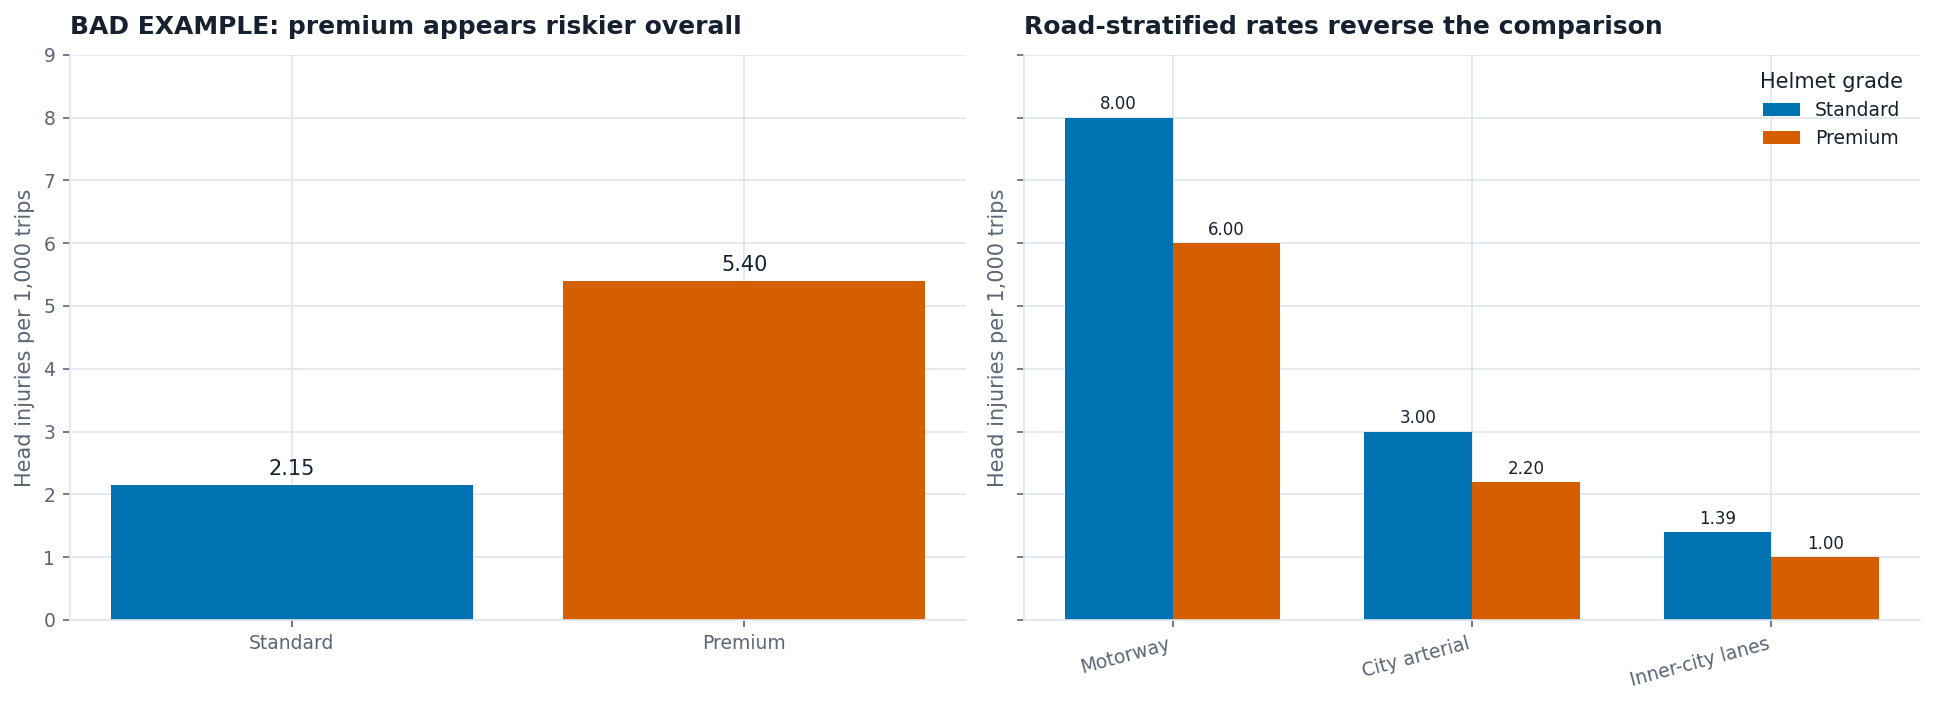

In [3]:
helmet = pd.read_csv(DATA_DIR / "case01_helmet_rickshaw.csv")

grade_summary = (
    helmet.groupby("helmet_grade", as_index=False)
    .agg(injuries=("head_injuries", "sum"), trips=("trips", "sum"))
)
grade_summary["injuries_per_1000"] = (
    1000 * grade_summary["injuries"] / grade_summary["trips"]
)
road_summary = (
    helmet.groupby(["road_type", "helmet_grade"], as_index=False)
    .agg(injuries=("head_injuries", "sum"), trips=("trips", "sum"))
)
road_summary["injuries_per_1000"] = (
    1000 * road_summary["injuries"] / road_summary["trips"]
)
road_order = ["Motorway", "City arterial", "Inner-city lanes"]
trip_mix = (
    helmet.groupby(["helmet_grade", "road_type"])["trips"].sum()
    .groupby(level=0, group_keys=False)
    .apply(lambda values: 100 * values / values.sum())
    .unstack()
)
speed_summary = helmet.groupby("helmet_grade")["avg_speed_kph"].mean()

print("Aggregate rates per 1,000 trips:")
display(grade_summary.set_index("helmet_grade").round(2))
print("Rates within road type:")
display(road_summary.pivot(index="road_type", columns="helmet_grade", values="injuries_per_1000").reindex(road_order).round(2))
print("Share of each grade's trips by road type (%):")
display(trip_mix.reindex(columns=road_order).round(1))
print("Mean rider speed by helmet grade (kph):")
display(speed_summary.round(1).rename("mean_speed_kph").to_frame())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
grade_order = ["Standard", "Premium"]
aggregate_rates = grade_summary.set_index("helmet_grade").loc[grade_order, "injuries_per_1000"]
bars = axes[0].bar(
    grade_order,
    aggregate_rates,
    color=[PALETTE_3[0], PALETTE_3[1]],
)
axes[0].bar_label(bars, fmt="%.2f", padding=3)
axes[0].set_ylim(0, 9)
axes[0].set_ylabel("Head injuries per 1,000 trips")
axes[0].set_title("BAD EXAMPLE: premium appears riskier overall")

x = np.arange(len(road_order))
width = 0.36
for offset, grade, color in [(-width / 2, "Standard", PALETTE_3[0]), (width / 2, "Premium", PALETTE_3[1])]:
    rates = (
        road_summary.loc[road_summary["helmet_grade"] == grade]
        .set_index("road_type")["injuries_per_1000"]
        .reindex(road_order)
    )
    bars = axes[1].bar(x + offset, rates, width, label=grade, color=color)
    axes[1].bar_label(bars, fmt="%.2f", padding=2, fontsize=8)
axes[1].set_xticks(x, road_order, rotation=15, ha="right")
axes[1].set_ylabel("Head injuries per 1,000 trips")
axes[1].set_title("Road-stratified rates reverse the comparison")
axes[1].legend(title="Helmet grade")
fig.tight_layout()
plt.show()

**Diagnosis and explanation.** The aggregate self-check is Standard 2.15 versus Premium 5.40 injuries per 1,000 trips (2.51×), but the comparison reverses in every road class: Premium is lower on motorways (6.00 vs 8.00), city arterials (2.20 vs 3.00), and inner-city lanes (1.00 vs 1.39). This is Simpson's paradox from different exposure mixes: 85% of Premium trips are on motorways, compared with 3.3% of Standard trips. Premium riders also average 67.0 kph versus 30.2 kph, so helmet grade is entangled with rider behaviour. The redesign stratifies by road type; it does not establish a causal helmet effect.

### A2 · Chai sales and quiz failures

Rebuild the 24-month scatterplot, least-squares line, and Pearson correlation. Test whether the raw-count relationship remains after accounting for the number of enrolled students.

Raw Pearson r: 0.982 (self-check 0.98)
r(cups, enrollment): 0.997
r(failures, enrollment): 0.977
Correlation of per-student rates: 0.293
Partial r controlling for enrollment: 0.455
Exam-month context:


,mean_failures_per_1000
is_exam_month,
0,34.15
1,38.62


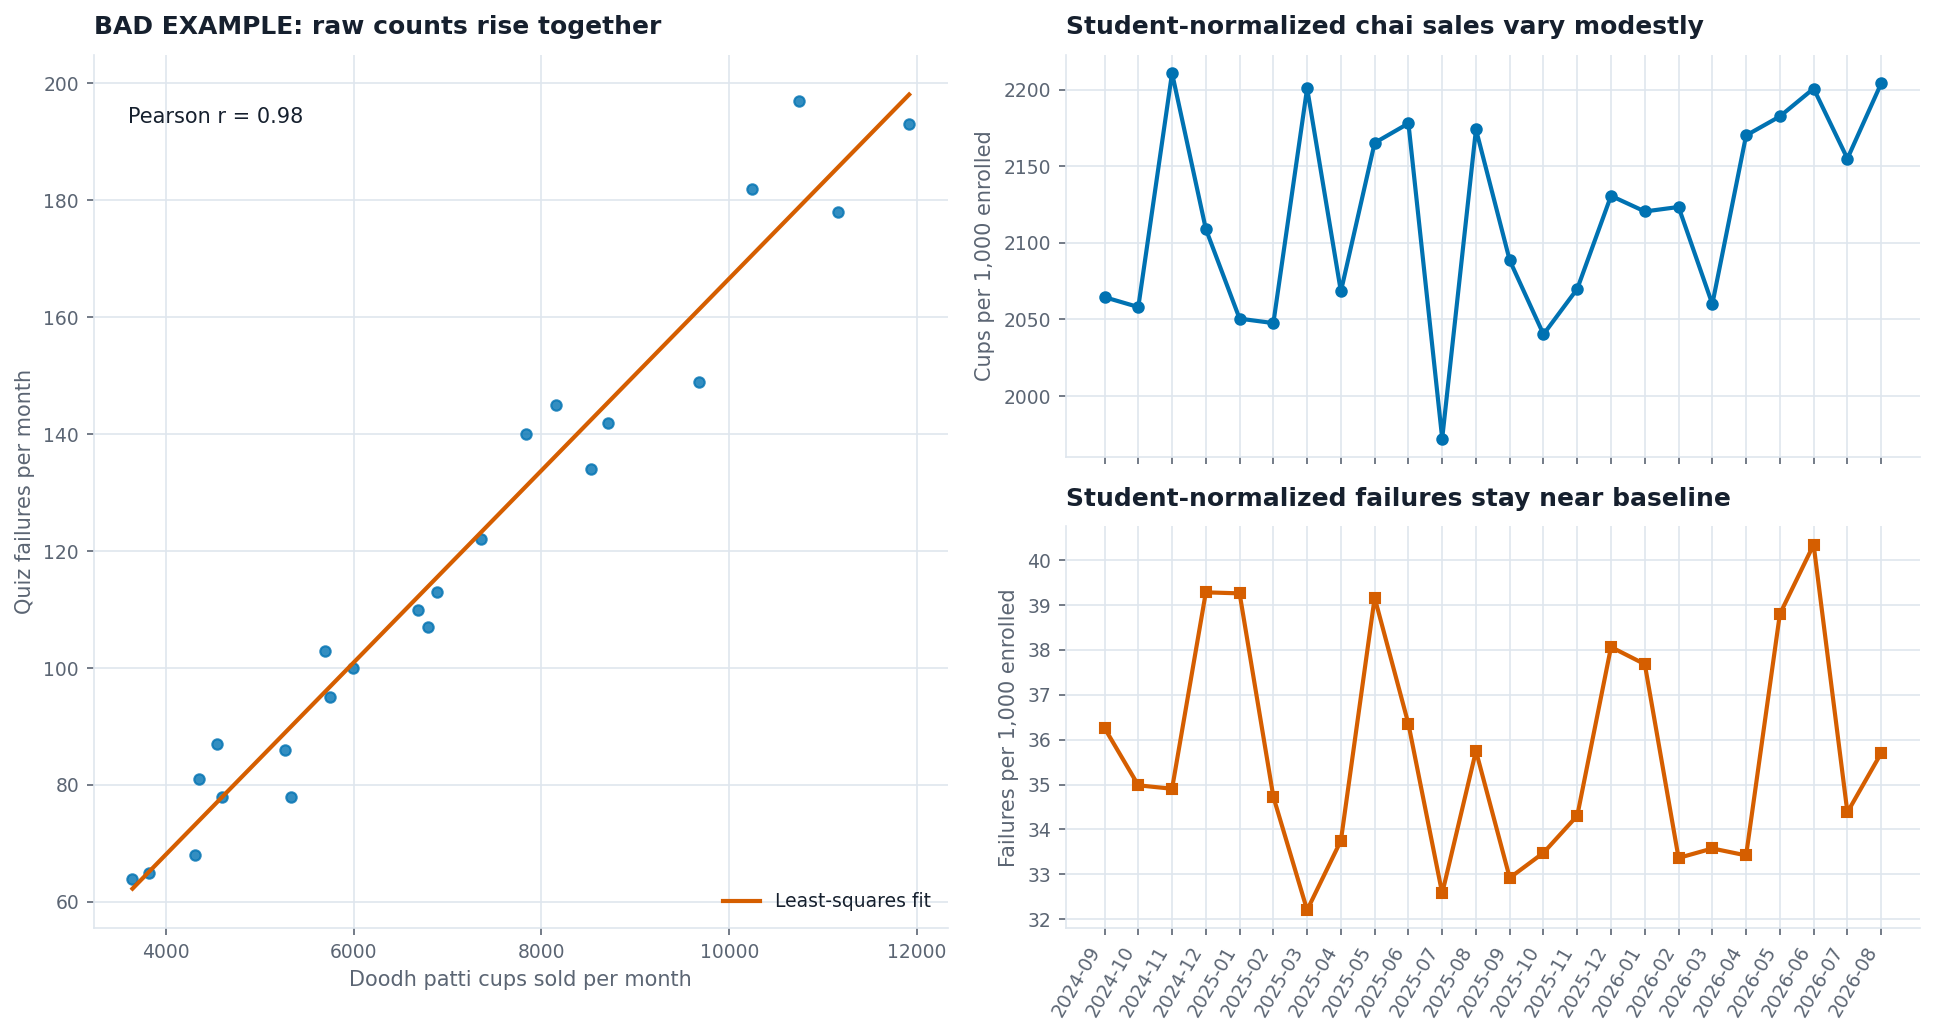

In [7]:
chai = pd.read_csv(DATA_DIR / "case02_chai_quizzes.csv")
chai["cups_per_1000_students"] = 1000 * chai["cups_doodh_patti_sold"] / chai["students_enrolled"]
chai["failures_per_1000_students"] = 1000 * chai["quiz_failures"] / chai["students_enrolled"]
raw_r = chai["cups_doodh_patti_sold"].corr(chai["quiz_failures"])

# Partial correlation after removing the linear effect of enrollment from both counts.
design = np.column_stack([np.ones(len(chai)), chai["students_enrolled"]])
cup_residuals = chai["cups_doodh_patti_sold"].to_numpy() - design @ np.linalg.lstsq(
    design, chai["cups_doodh_patti_sold"].to_numpy(), rcond=None
)[0]
failure_residuals = chai["quiz_failures"].to_numpy() - design @ np.linalg.lstsq(
    design, chai["quiz_failures"].to_numpy(), rcond=None
)[0]
partial_r = np.corrcoef(cup_residuals, failure_residuals)[0, 1]
rate_r = chai["cups_per_1000_students"].corr(chai["failures_per_1000_students"])

print(f"Raw Pearson r: {raw_r:.3f} (self-check 0.98)")
print(f"r(cups, enrollment): {chai['cups_doodh_patti_sold'].corr(chai['students_enrolled']):.3f}")
print(f"r(failures, enrollment): {chai['quiz_failures'].corr(chai['students_enrolled']):.3f}")
print(f"Correlation of per-student rates: {rate_r:.3f}")
print(f"Partial r controlling for enrollment: {partial_r:.3f}")
print("Exam-month context:")
display(chai.groupby("is_exam_month")["failures_per_1000_students"].mean().round(2).rename("mean_failures_per_1000").to_frame())

month_index = np.arange(len(chai))
slope, intercept = np.polyfit(chai["cups_doodh_patti_sold"], chai["quiz_failures"], 1)
x_line = np.linspace(chai["cups_doodh_patti_sold"].min(), chai["cups_doodh_patti_sold"].max(), 100)
fig = plt.figure(figsize=(13, 7))
grid = fig.add_gridspec(2, 2)
bad_ax = fig.add_subplot(grid[:, 0])
cups_ax = fig.add_subplot(grid[0, 1])
failures_ax = fig.add_subplot(grid[1, 1], sharex=cups_ax)

bad_ax.scatter(chai["cups_doodh_patti_sold"], chai["quiz_failures"], color=PALETTE_3[0], alpha=0.8)
bad_ax.plot(x_line, intercept + slope * x_line, color=PALETTE_3[1], label="Least-squares fit")
bad_ax.text(0.04, 0.94, f"Pearson r = {raw_r:.2f}", transform=bad_ax.transAxes, va="top")
bad_ax.set_xlabel("Doodh patti cups sold per month")
bad_ax.set_ylabel("Quiz failures per month")
bad_ax.set_title("BAD EXAMPLE: raw counts rise together")
bad_ax.legend(loc="lower right")

cups_ax.plot(month_index, chai["cups_per_1000_students"], marker="o", color=PALETTE_3[0])
cups_ax.set_ylabel("Cups per 1,000 enrolled")
cups_ax.set_title("Student-normalized chai sales vary modestly")
cups_ax.tick_params(axis="x", labelbottom=False)
failures_ax.plot(month_index, chai["failures_per_1000_students"], marker="s", color=PALETTE_3[1])
failures_ax.set_ylabel("Failures per 1,000 enrolled")
failures_ax.set_title("Student-normalized failures stay near baseline")
failures_ax.set_xticks(month_index, chai["month"], rotation=60, ha="right")
fig.tight_layout()
plt.show()

**Diagnosis and explanation.** The raw-count self-check is r = 0.982, but enrollment also rises from 1,765 to 5,406 and correlates with both chai sales (r = 0.997) and failures (r = 0.977). Enrollment is the shared exposure driving much of the apparent relationship: after dividing both monthly counts by enrollment, their correlation is 0.293 (0.455 after linear adjustment for enrollment). Exam months still have more failures per 1,000 students on average (38.62 vs 34.15), so enrollment adjustment is not a causal model and exam timing remains relevant. The redesign shows each normalized series separately over time.

### A3 · AQI before and after the action plan

Rebuild the daily mean across all reporting rows, marking day 61 and the two period means. Then inspect station coverage and compare only the stations that report in both periods.

All-reporters means: before=202.09, after=137.21
Reporting stations each day: 22 before day 61; 13 from day 61 onward
Stations reporting after day 60: 13 (LHR-10, LHR-11, LHR-12, LHR-13, LHR-14, LHR-15, LHR-16, LHR-17, LHR-18, LHR-19, LHR-20, LHR-21, LHR-22)
Same-station means: before=137.09, after=137.21
Mean AQI and reporting rows by zone and period:


mean_aqi  reports
period      zone                          
Days 1–60   Arterial       244.70      360
            Industrial     322.04      360
            Peri-urban      78.95      240
            Residential    121.64      360
Days 61–120 Arterial       245.87      180
            Industrial        NaN        0
            Peri-urban      80.39      240
            Residential    120.75      360

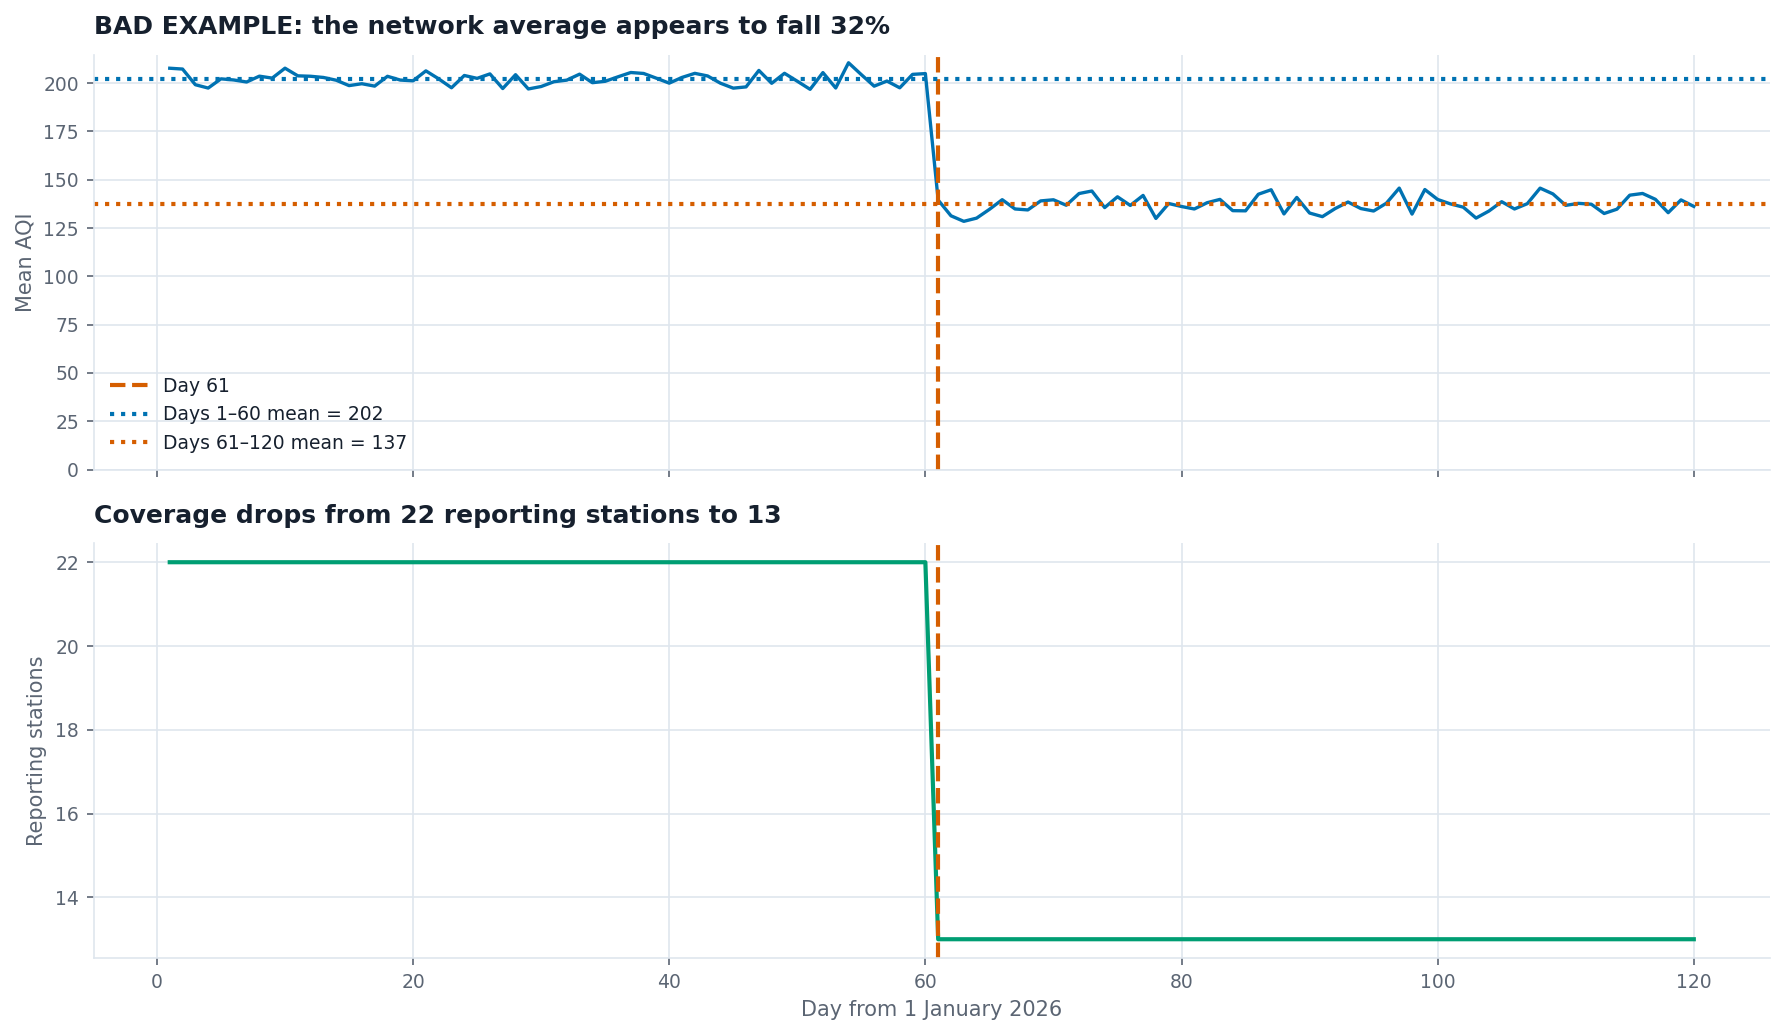

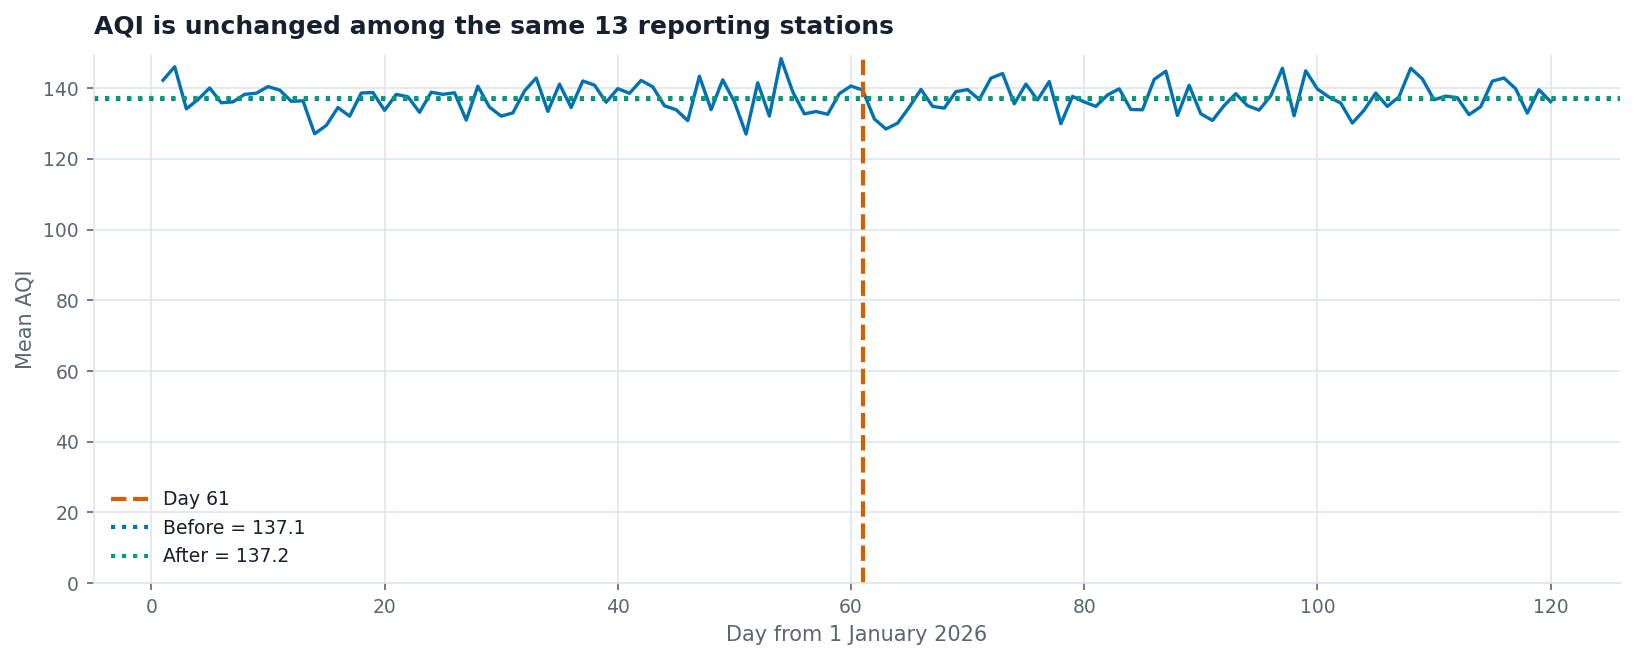

In [9]:
aqi = pd.read_csv(DATA_DIR / "case03_aqi_monitors.csv", parse_dates=["date"])
aq_date_day = {date: day for day, date in enumerate(sorted(aqi["date"].unique()), start=1)}
aqi["day"] = aqi["date"].map(aq_date_day)
aqi_daily = (
    aqi.groupby(["date", "day"], as_index=False)
    .agg(mean_aqi=("aqi", "mean"), stations_reporting=("aqi", "count"))
)
overall_before = aqi_daily.loc[aqi_daily["day"] <= 60, "mean_aqi"].mean()
overall_after = aqi_daily.loc[aqi_daily["day"] > 60, "mean_aqi"].mean()
common_stations = sorted(aqi.loc[(aqi["day"] > 60) & aqi["aqi"].notna(), "station_id"].unique())
common_daily = (
    aqi.loc[aqi["station_id"].isin(common_stations)]
    .groupby(["date", "day"], as_index=False)
    .agg(mean_aqi=("aqi", "mean"))
)
common_before = common_daily.loc[common_daily["day"] <= 60, "mean_aqi"].mean()
common_after = common_daily.loc[common_daily["day"] > 60, "mean_aqi"].mean()
reporting_before = int(aqi_daily.loc[aqi_daily["day"] <= 60, "stations_reporting"].min())
reporting_after = int(aqi_daily.loc[aqi_daily["day"] > 60, "stations_reporting"].min())

print(f"All-reporters means: before={overall_before:.2f}, after={overall_after:.2f}")
print(f"Reporting stations each day: {reporting_before} before day 61; {reporting_after} from day 61 onward")
print(f"Stations reporting after day 60: {len(common_stations)} ({', '.join(common_stations)})")
print(f"Same-station means: before={common_before:.2f}, after={common_after:.2f}")
print("Mean AQI and reporting rows by zone and period:")
aqi["period"] = np.where(aqi["day"] <= 60, "Days 1–60", "Days 61–120")
display(aqi.groupby(["period", "zone"]).agg(mean_aqi=("aqi", "mean"), reports=("aqi", "count")).round(2))

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
axes[0].plot(aqi_daily["day"], aqi_daily["mean_aqi"], color=PALETTE_3[0], linewidth=1.6)
axes[0].axvline(61, color=PALETTE_3[1], linestyle="--", label="Day 61")
axes[0].axhline(overall_before, color=PALETTE_3[0], linestyle=":", label=f"Days 1–60 mean = {overall_before:.0f}")
axes[0].axhline(overall_after, color=PALETTE_3[1], linestyle=":", label=f"Days 61–120 mean = {overall_after:.0f}")
axes[0].set_ylim(bottom=0)
axes[0].set_ylabel("Mean AQI")
axes[0].set_title("BAD EXAMPLE: the network average appears to fall 32%")
axes[0].legend(ncol=1, loc="lower left")
axes[1].plot(aqi_daily["day"], aqi_daily["stations_reporting"], color=PALETTE_3[2])
axes[1].axvline(61, color=PALETTE_3[1], linestyle="--")
axes[1].set_ylabel("Reporting stations")
axes[1].set_xlabel("Day from 1 January 2026")
axes[1].set_title("Coverage drops from 22 reporting stations to 13")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(common_daily["day"], common_daily["mean_aqi"], color=PALETTE_3[0], linewidth=1.6)
ax.axvline(61, color=PALETTE_3[1], linestyle="--", label="Day 61")
ax.axhline(common_before, color=PALETTE_3[0], linestyle=":", label=f"Before = {common_before:.1f}")
ax.axhline(common_after, color=PALETTE_3[2], linestyle=":", label=f"After = {common_after:.1f}")
ax.set_ylim(bottom=0)
ax.set_xlabel("Day from 1 January 2026")
ax.set_ylabel("Mean AQI")
ax.set_title("AQI is unchanged among the same 13 reporting stations")
ax.legend(loc="lower left")
fig.tight_layout()
plt.show()

**Diagnosis and explanation.** The required all-row calculation reproduces the self-check: mean AQI falls from 202.09 to 137.21 (about 32%). The mechanism is changing station composition, not a demonstrated policy effect: coverage falls from 22 stations per day to 13, and all six Industrial stations have zero readings after day 60. Among the same 13 stations that report in both periods, the mean is 137.09 before and 137.21 after. The redesign holds station coverage constant; it does not claim the AQI improved.

### A4 · Department summary statistics hide the shape

Produce the requested table by department, then plot each group. Check whether identical means and correlations imply similar student-level patterns.

Requested department summary (sample SD):


,n,mean_hours,mean_score,sd_hours,sd_score,pearson_r,slope_score_per_hour
department,,,,,,,
Architecture,11,18.0,14.501,6.633,2.031,0.817,0.25
Business Administration,11,18.0,14.501,6.633,2.032,0.816,0.25
Computer Science,11,18.0,14.501,6.633,2.032,0.816,0.25
Electrical Engineering,11,18.0,14.500,6.633,2.030,0.816,0.25


Architecture's repeated study-hour value and the high-leverage observation:


,count,mean
study_hours_per_week,,
16.0,10,14.0
38.0,1,19.5


Among the ten 16-hour students, SD(study hours) = 0.0; their correlation is undefined because study hours do not vary.


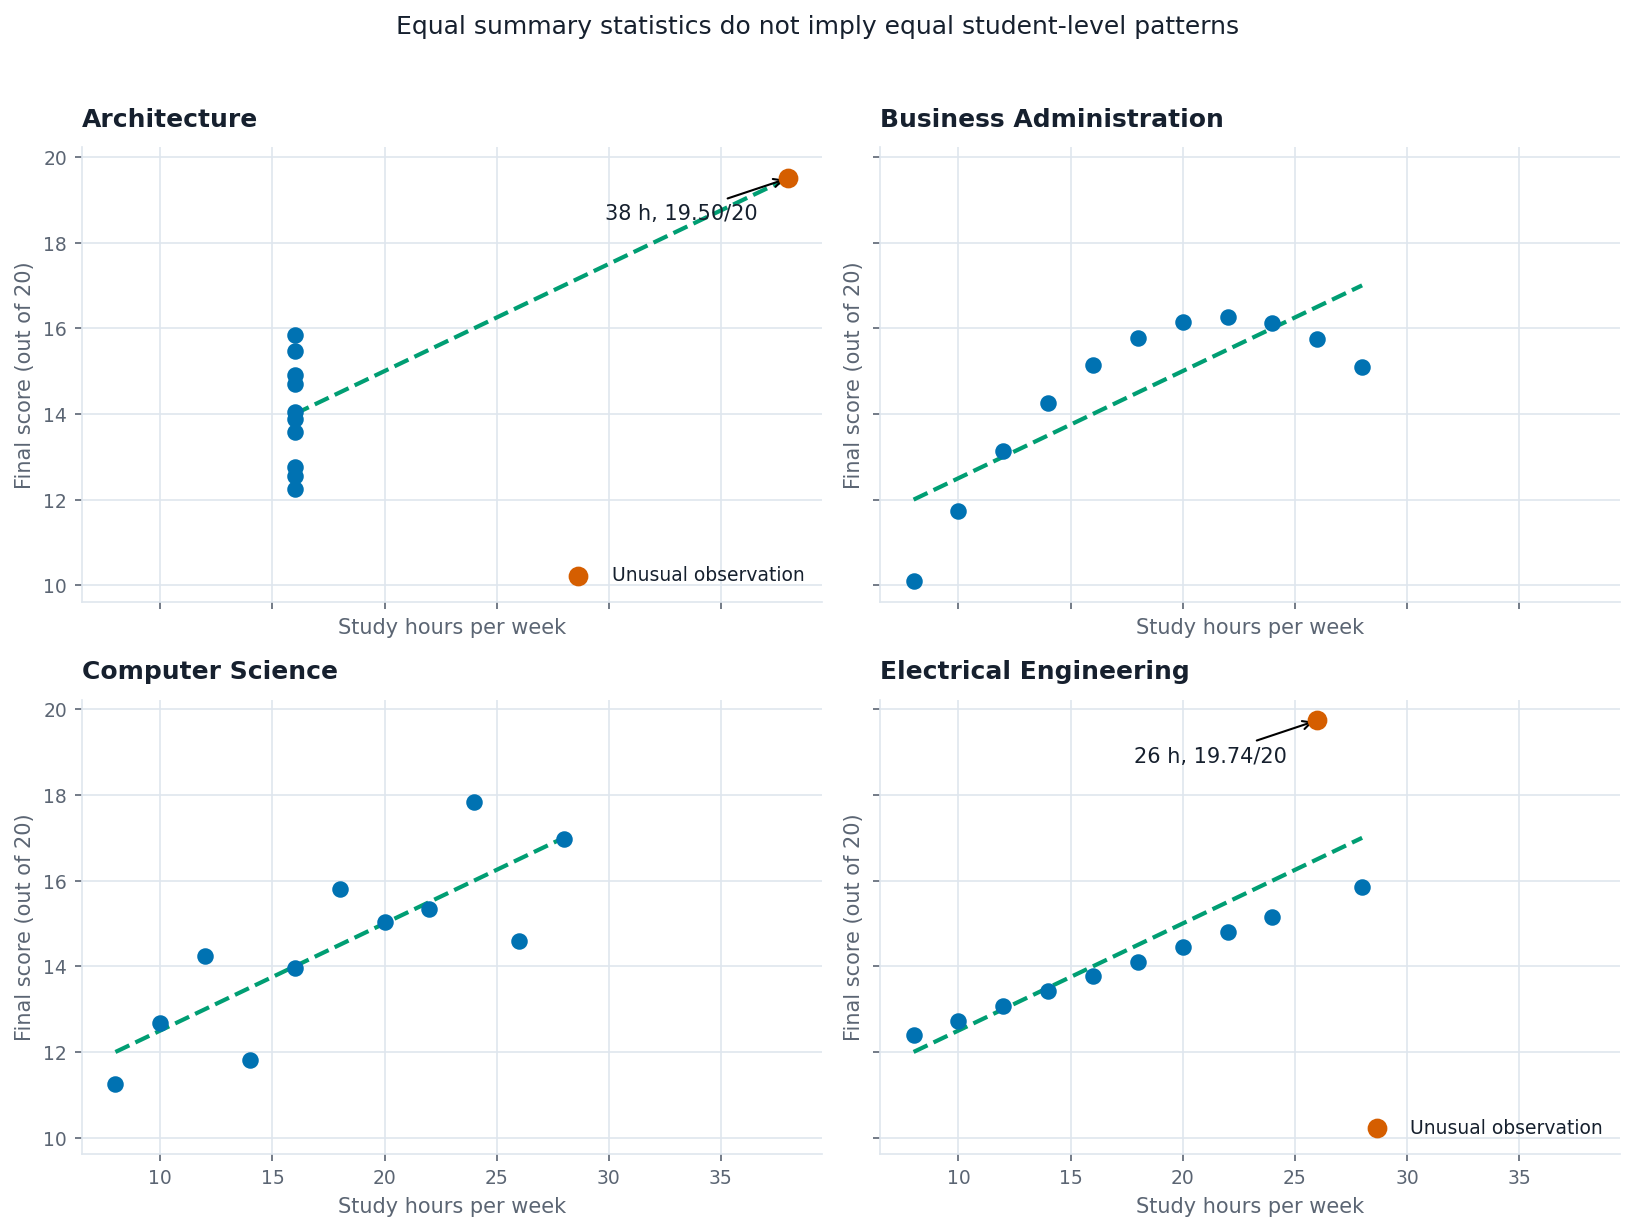

In [11]:
quartet = pd.read_csv(DATA_DIR / "case04_quartet_depts.csv")
summary_rows = []
for department, group in quartet.groupby("department", sort=True):
    hours = group["study_hours_per_week"]
    score = group["final_score_out_of_20"]
    summary_rows.append({
        "department": department,
        "n": len(group),
        "mean_hours": hours.mean(),
        "mean_score": score.mean(),
        "sd_hours": hours.std(ddof=1),
        "sd_score": score.std(ddof=1),
        "pearson_r": hours.corr(score),
        "slope_score_per_hour": np.polyfit(hours, score, 1)[0],
    })
department_summary = pd.DataFrame(summary_rows).set_index("department")
print("Requested department summary (sample SD):")
display(department_summary.round(3))

architecture = quartet.loc[quartet["department"] == "Architecture"]
architecture_typical = architecture.loc[architecture["study_hours_per_week"] == 16]
print("Architecture's repeated study-hour value and the high-leverage observation:")
display(architecture.groupby("study_hours_per_week")["final_score_out_of_20"].agg(["count", "mean"]).round(2))
print(f"Among the ten 16-hour students, SD(study hours) = {architecture_typical['study_hours_per_week'].std(ddof=1):.1f}; their correlation is undefined because study hours do not vary.")

fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharex=True, sharey=True)
for ax, (department, group) in zip(axes.flat, quartet.groupby("department", sort=True)):
    hours = group["study_hours_per_week"]
    score = group["final_score_out_of_20"]
    ax.scatter(hours, score, color=PALETTE_3[0], s=48, zorder=3)
    fit_x = np.linspace(hours.min(), hours.max(), 100)
    slope, intercept = np.polyfit(hours, score, 1)
    ax.plot(fit_x, intercept + slope * fit_x, color=PALETTE_3[2], linestyle="--")
    ax.set_title(department)
    ax.set_xlabel("Study hours per week")
    ax.set_ylabel("Final score (out of 20)")
    if department == "Architecture":
        point_x, point_y = 38, 19.5
        label = "38 h, 19.50/20"
    elif department == "Electrical Engineering":
        point_x, point_y = 26, 19.74
        label = "26 h, 19.74/20"
    else:
        continue
    ax.scatter([point_x], [point_y], color=PALETTE_3[1], s=72, zorder=4, label="Unusual observation")
    ax.annotate(label, (point_x, point_y), xytext=(-88, -20), textcoords="offset points", arrowprops={"arrowstyle": "->"})
    ax.legend(loc="lower right")
fig.suptitle("Equal summary statistics do not imply equal student-level patterns", y=1.02)
fig.tight_layout()
plt.show()

**Diagnosis and explanation.** All four groups match the summary self-check to rounding (n = 11, mean hours = 18.00, mean score = 14.50, r ≈ 0.816, slope ≈ 0.25), but the scatterplots are not interchangeable. Architecture has ten students at exactly 16 hours and one at 38 hours with score 19.50; that single high-leverage observation supplies all of the study-hour variation. The other ten have SD(hours) = 0, so their correlation is undefined. Electrical Engineering also contains a notably high score (19.74 at 26 hours). Equal moments hide different distributions and point configurations, so they do not justify identical funding.

### A5 · Same statistics, different shapes

Build the requested cohort table using population SDs so it can be compared with the exact target moments. Then plot all five cohorts on common axes.

Cohort statistics (population SD, matching the generation targets):


,n,mean_hours,mean_score,sd_hours_population,sd_score_population,pearson_r
shape_name,,,,,,
straight line,180,48.0,63.0,12.0,15.0,0.42
ring,180,48.0,63.0,12.0,15.0,0.42
star,180,48.0,63.0,12.0,15.0,0.42
two clusters,180,48.0,63.0,12.0,15.0,0.42
the letter X,180,48.0,63.0,12.0,15.0,0.42


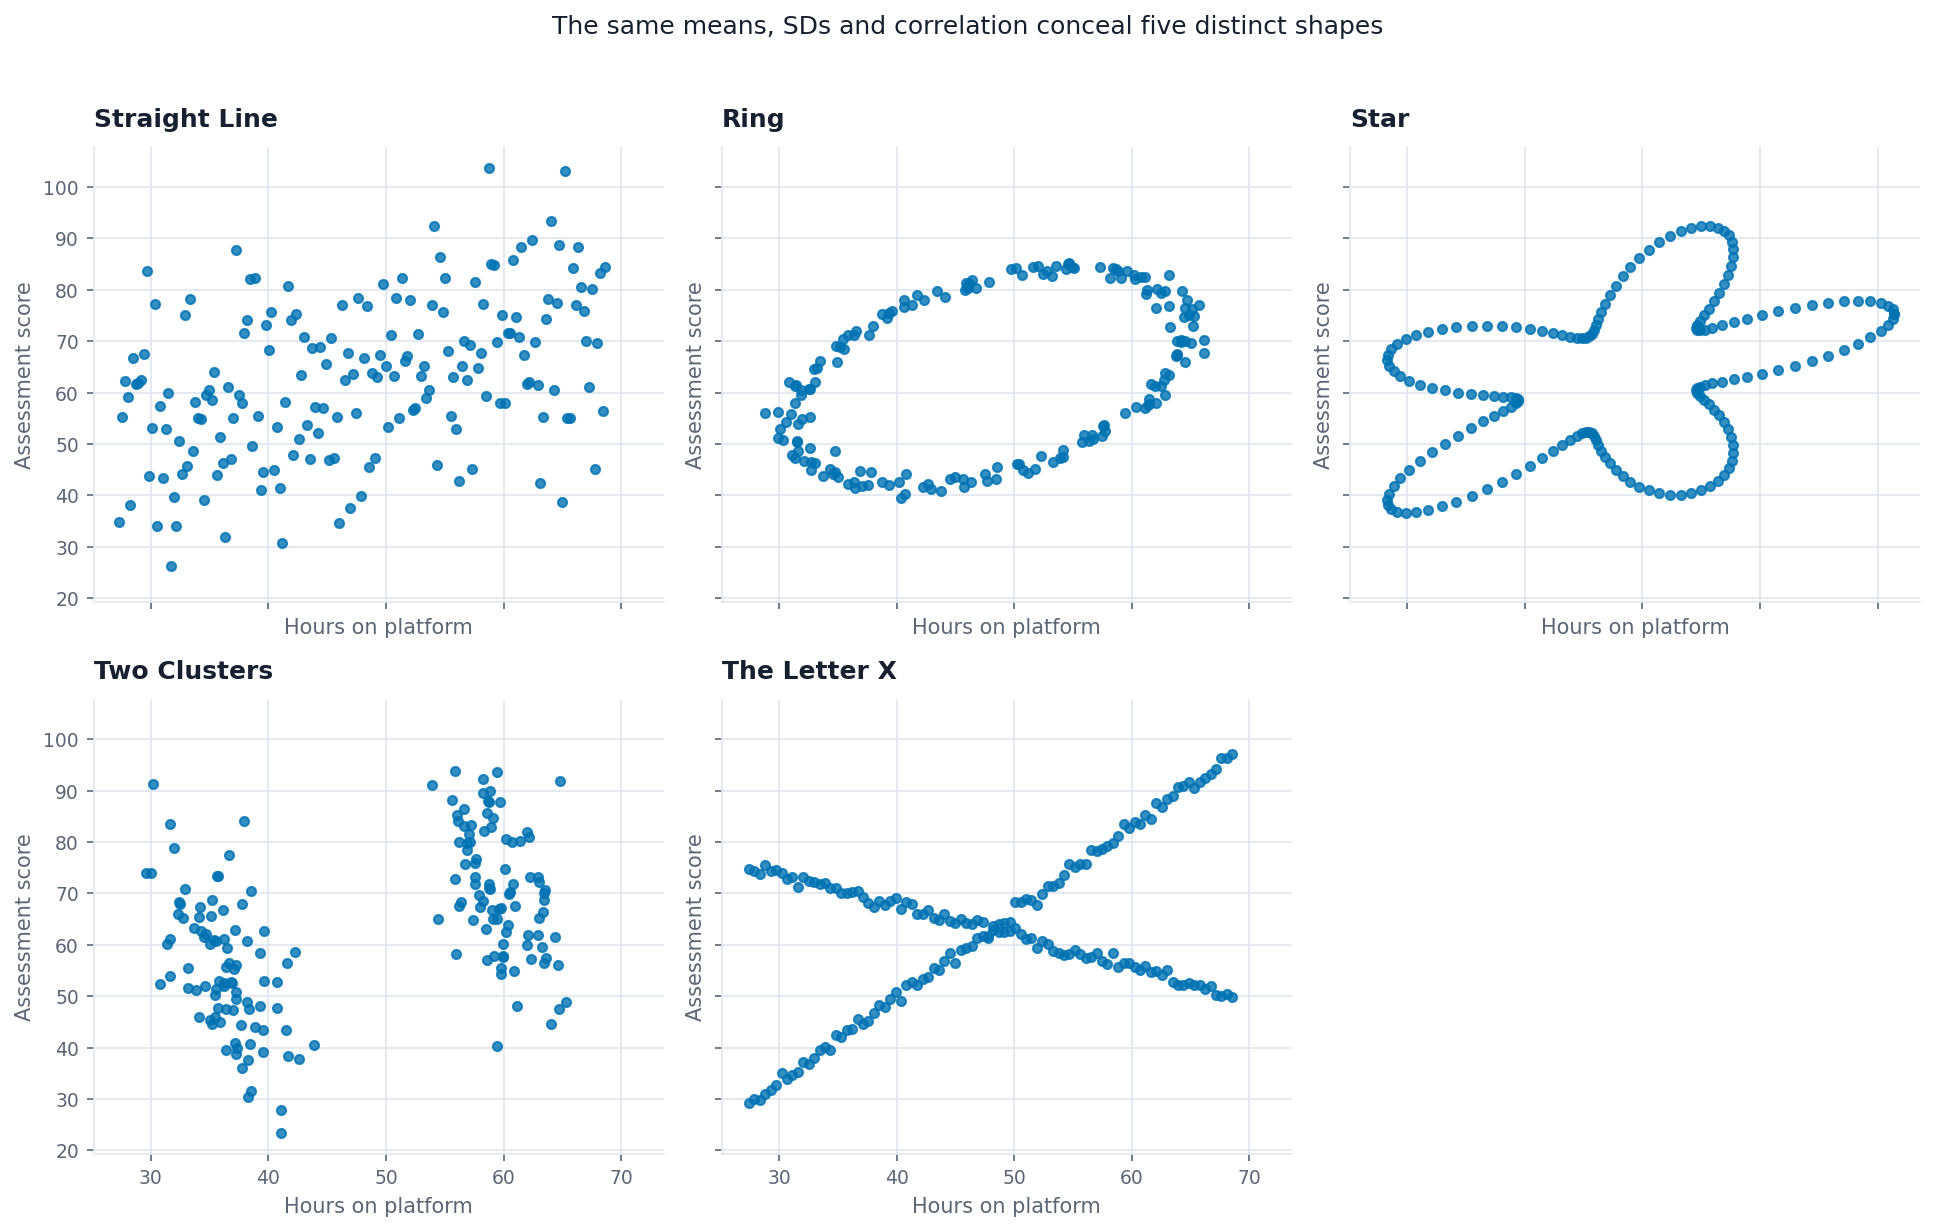

In [12]:
shapes = pd.read_csv(DATA_DIR / "case05_same_stats_shapes.csv")
shape_order = ["straight line", "ring", "star", "two clusters", "the letter X"]
shape_rows = []
for shape_name in shape_order:
    group = shapes.loc[shapes["shape_name"] == shape_name]
    shape_rows.append({
        "shape_name": shape_name,
        "n": len(group),
        "mean_hours": group["hours_on_platform"].mean(),
        "mean_score": group["assessment_score"].mean(),
        "sd_hours_population": group["hours_on_platform"].std(ddof=0),
        "sd_score_population": group["assessment_score"].std(ddof=0),
        "pearson_r": group["hours_on_platform"].corr(group["assessment_score"]),
    })
shape_summary = pd.DataFrame(shape_rows).set_index("shape_name")
print("Cohort statistics (population SD, matching the generation targets):")
display(shape_summary.round(3))

fig, axes = plt.subplots(2, 3, figsize=(13, 8), sharex=True, sharey=True)
for ax, shape_name in zip(axes.flat, shape_order):
    group = shapes.loc[shapes["shape_name"] == shape_name]
    ax.scatter(group["hours_on_platform"], group["assessment_score"], color=PALETTE_3[0], s=19, alpha=0.8)
    ax.set_title(shape_name.title())
    ax.set_xlabel("Hours on platform")
    ax.set_ylabel("Assessment score")
axes.flat[-1].set_visible(False)
fig.suptitle("The same means, SDs and correlation conceal five distinct shapes", y=1.02)
fig.tight_layout()
plt.show()

**Diagnosis and explanation.** Every cohort has n = 180, mean (48, 63), population SD (12, 15), and r = 0.420, matching the self-check. Yet the scatterplots show a noisy straight trend, a ring, a star, two clusters, and an X. Identical first- and second-order summaries do not describe distribution shape, subgroup structure, or nonlinear pattern. The honest redesign is to inspect the points directly alongside the table, not to choose one cohort as representative from summary statistics alone.

### A6 · The correlation heatmap can mislead twice

Rebuild the 20 × 20 numeric correlation matrix as the analyst drew it, then correct the visual encoding. Also inspect whether the headline creatinine–HbA1c association is consistent across study sites.

Correlation matrix dimensions: 20 × 20
creatinine ↔ hba1c: 0.765 (self-check 0.77)
systolic ↔ map_mmhg: 0.958 (self-check 0.96)
The pooled biomarker correlation varies by study site:


,n,hba1c_creatinine_r
study_site,,
Site A,45,-0.049
Site B,40,0.342
Site C,46,0.918
Site D,49,-0.114


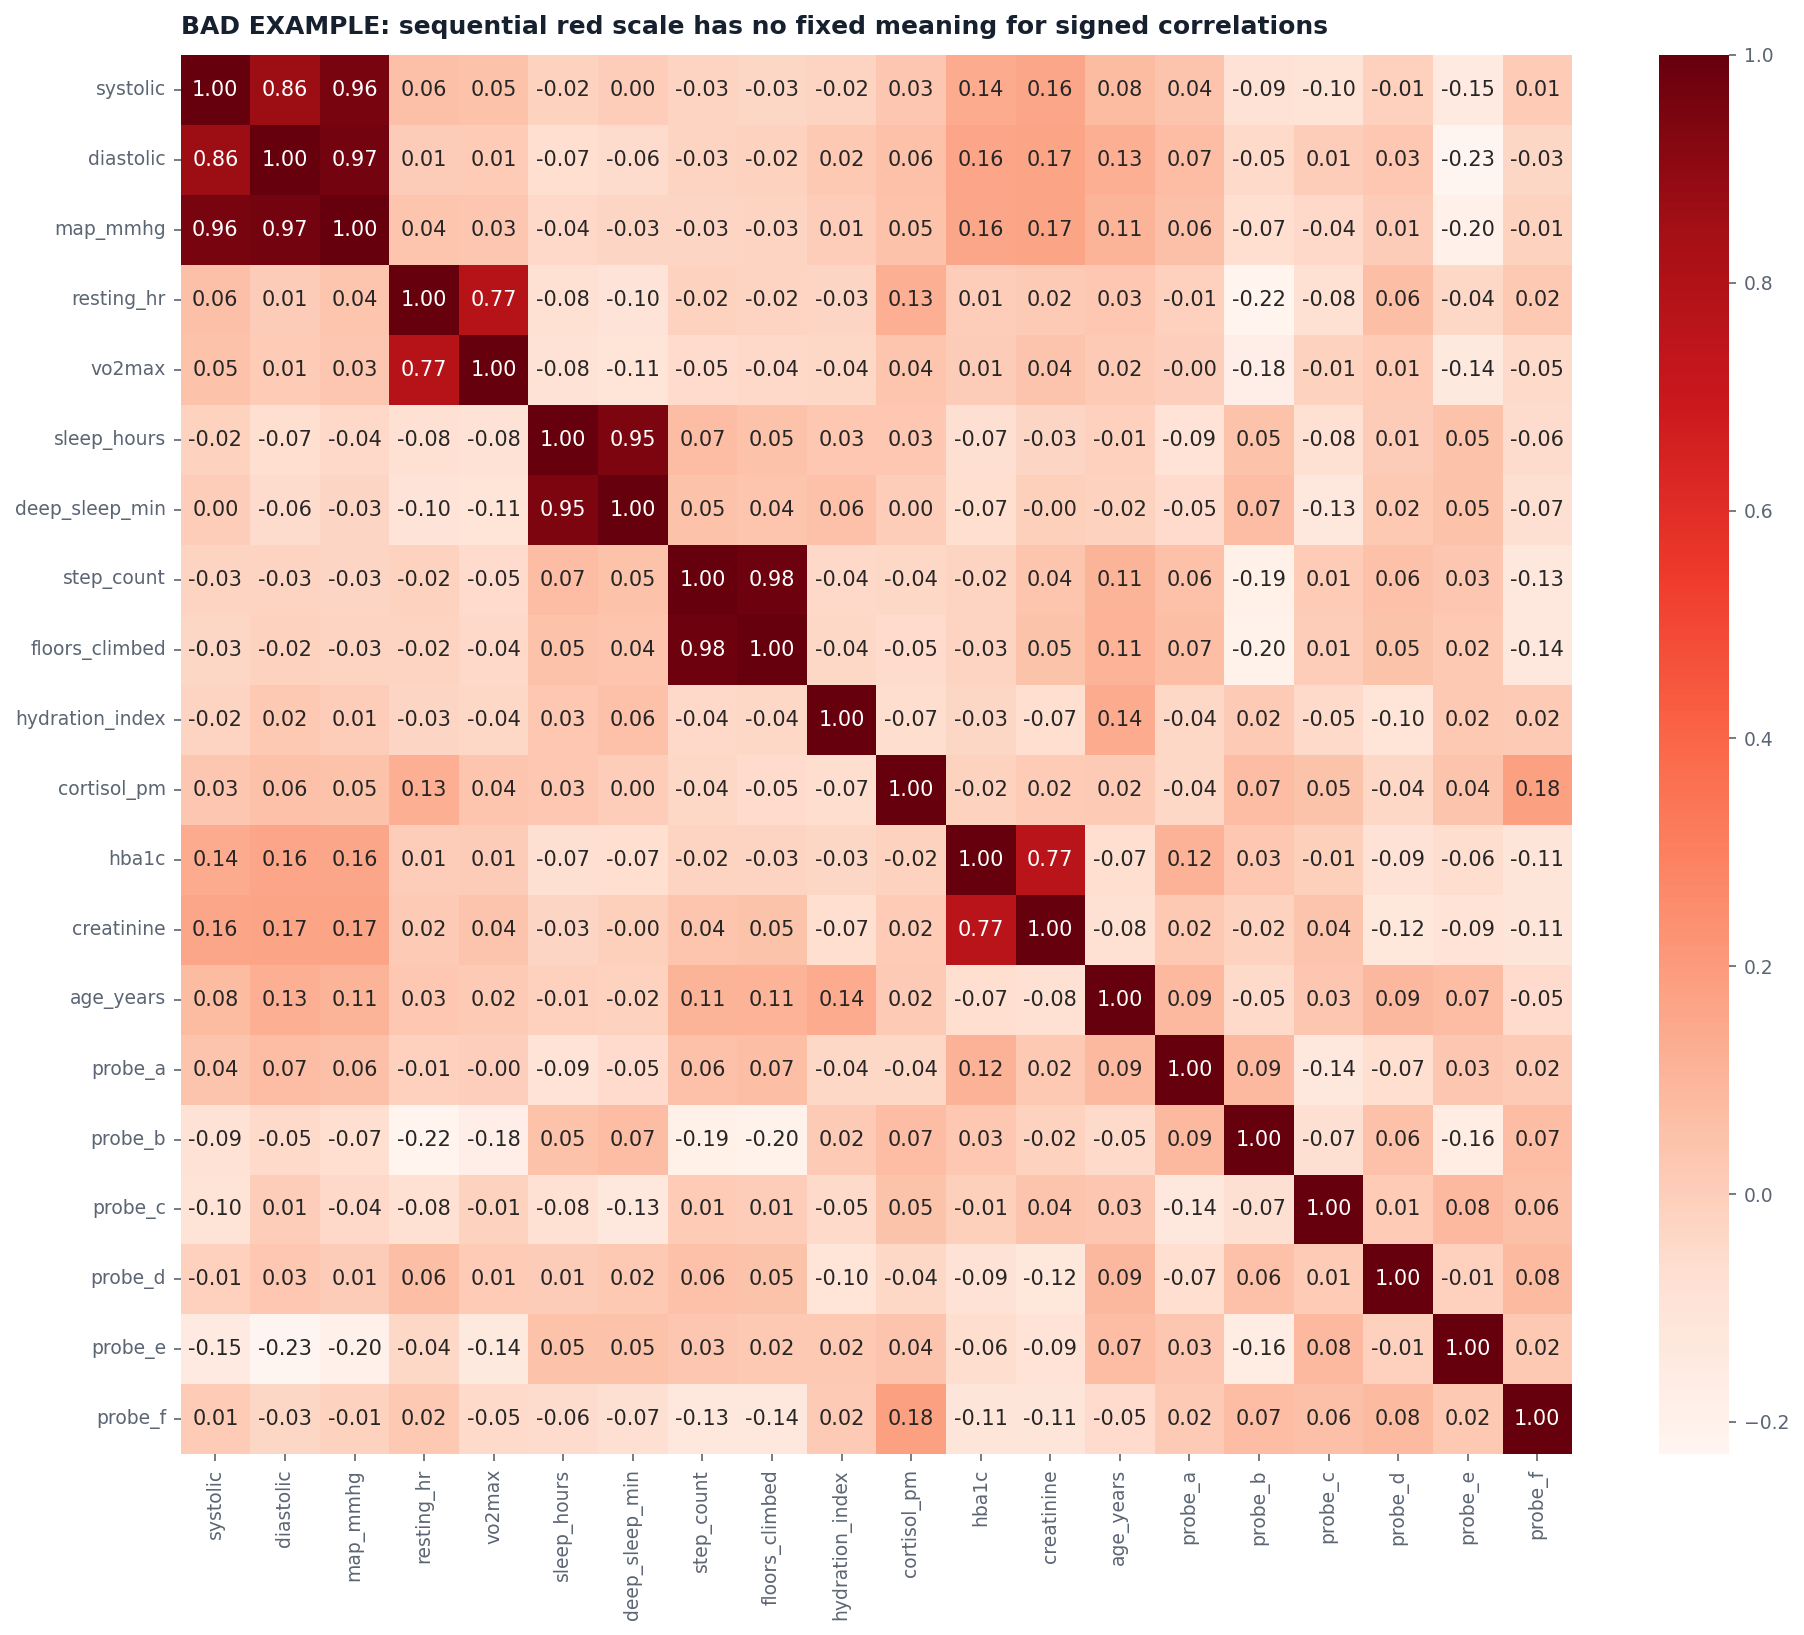

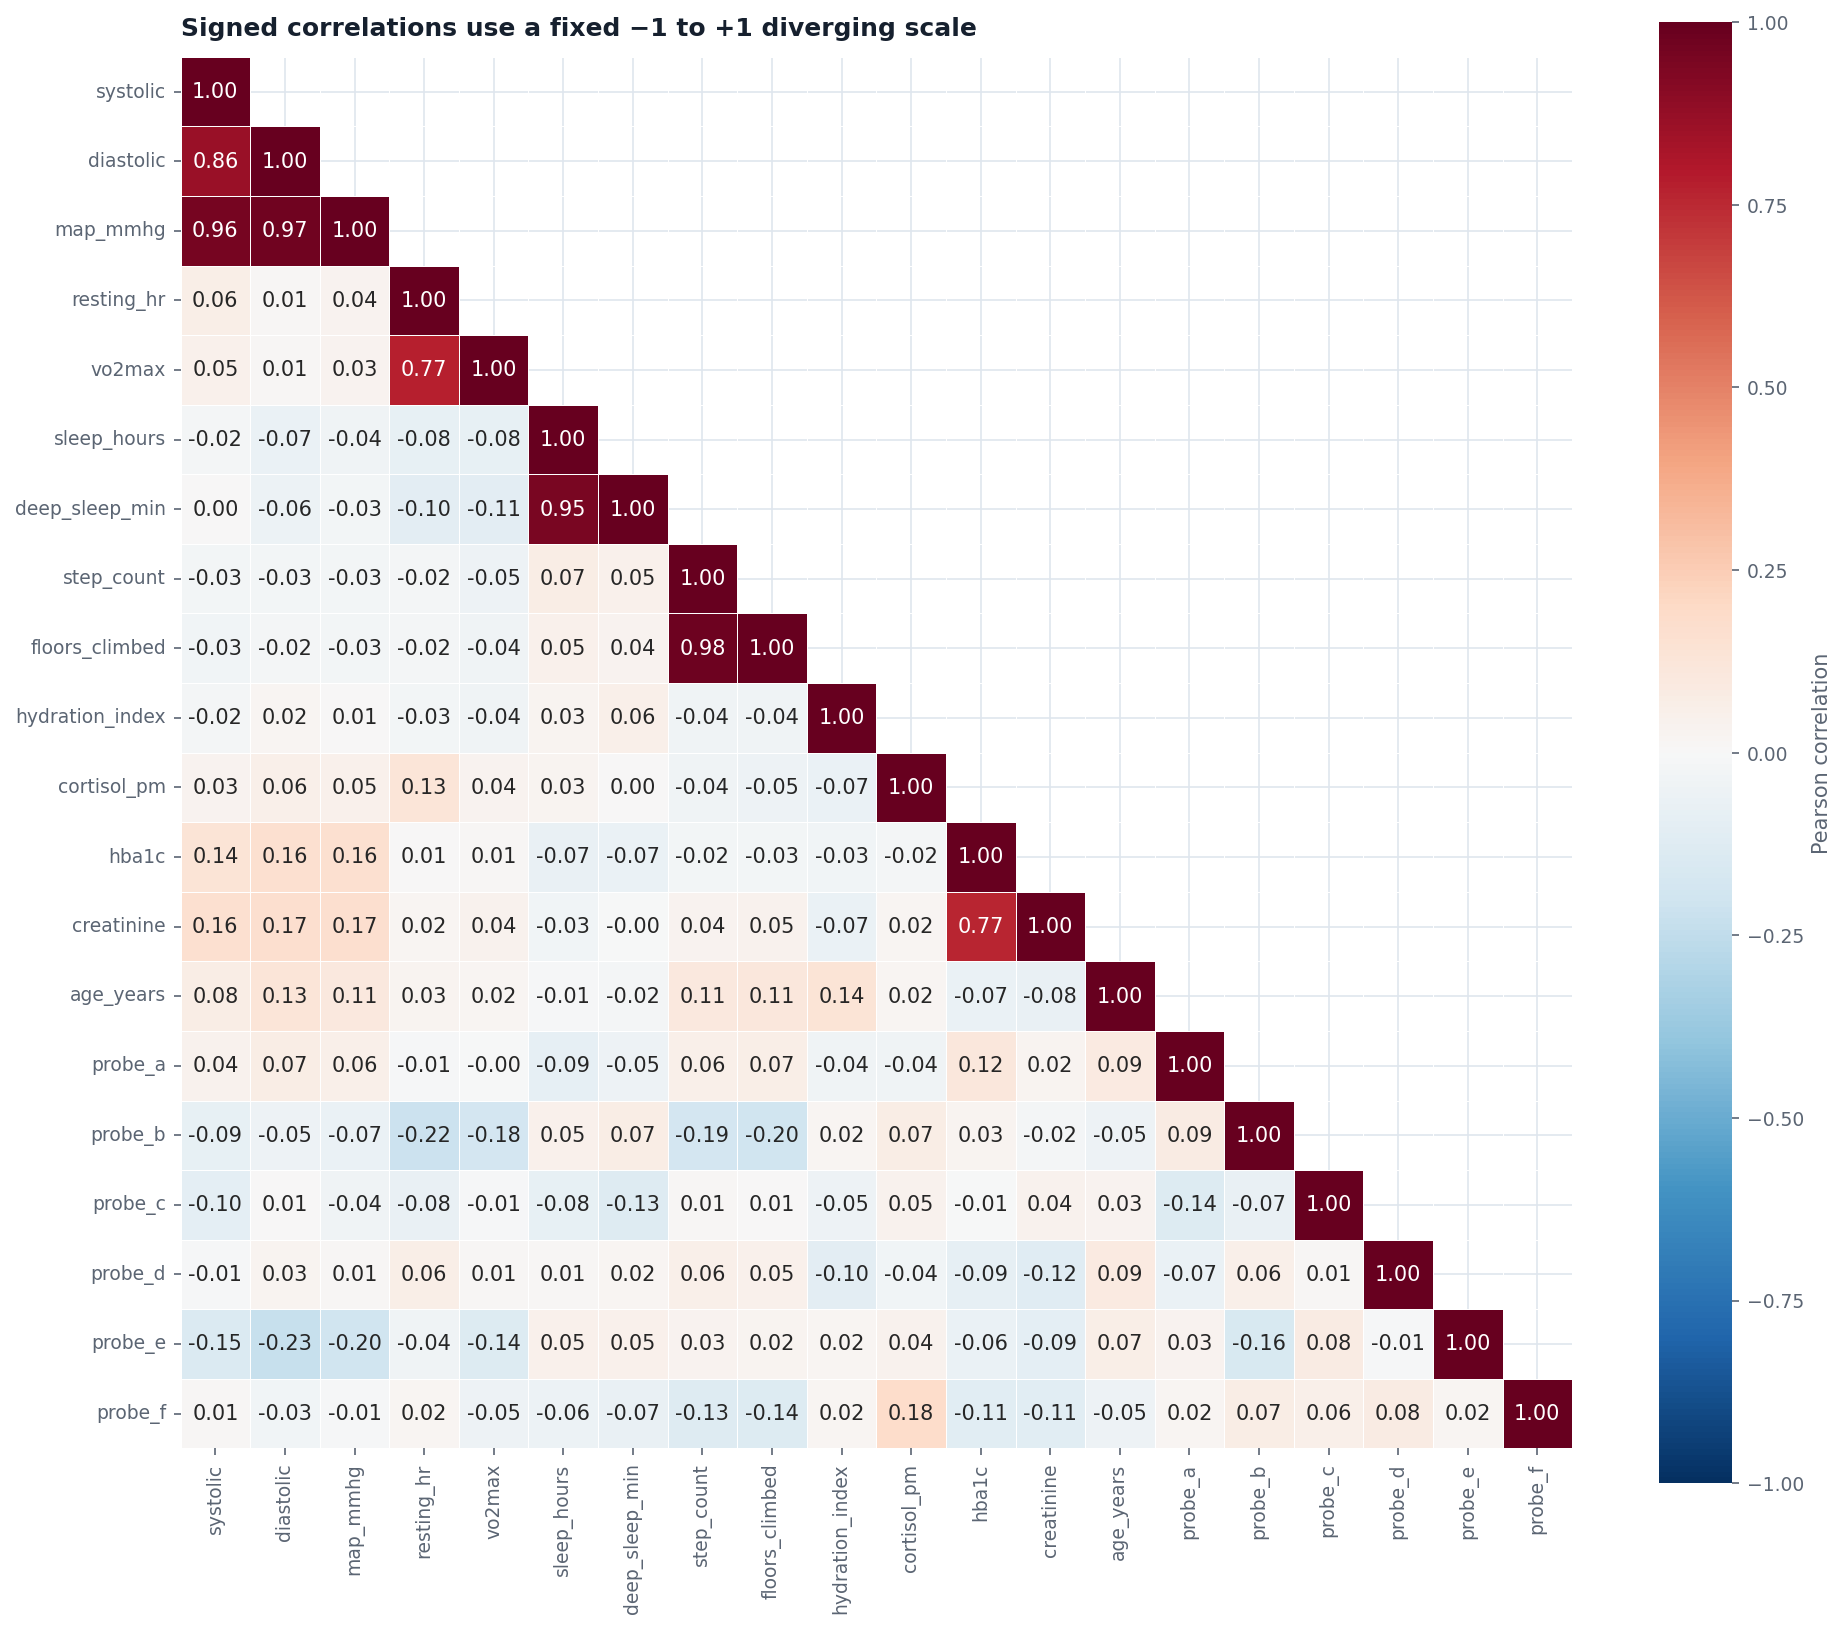

In [13]:
sensors = pd.read_csv(DATA_DIR / "case06_sensor_matrix.csv")
excluded_columns = {"age_band", "study_site", "hr_device_model"}
numeric_columns = [
    column for column in sensors.select_dtypes(include=np.number).columns
    if column not in excluded_columns
]
sensor_corr = sensors[numeric_columns].corr()
assert sensor_corr.shape == (20, 20)
print(f"Correlation matrix dimensions: {sensor_corr.shape[0]} × {sensor_corr.shape[1]}")
print(f"creatinine ↔ hba1c: {sensor_corr.loc['creatinine', 'hba1c']:.3f} (self-check 0.77)")
print(f"systolic ↔ map_mmhg: {sensor_corr.loc['systolic', 'map_mmhg']:.3f} (self-check 0.96)")
site_correlations = pd.DataFrame([
    {
        "study_site": site,
        "n": len(group),
        "hba1c_creatinine_r": group["hba1c"].corr(group["creatinine"]),
    }
    for site, group in sensors.groupby("study_site", sort=True)
]).set_index("study_site")
print("The pooled biomarker correlation varies by study site:")
display(site_correlations.round(3))

fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(sensor_corr, cmap="Reds", annot=True, fmt=".2f", ax=ax)
ax.set_title("BAD EXAMPLE: sequential red scale has no fixed meaning for signed correlations")
fig.tight_layout()
plt.show()

upper_triangle = np.triu(np.ones(sensor_corr.shape, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(
    sensor_corr,
    mask=upper_triangle,
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    center=0,
    annot=True,
    fmt=".2f",
    square=True,
    linewidths=0.25,
    cbar_kws={"label": "Pearson correlation"},
    ax=ax,
)
ax.set_title("Signed correlations use a fixed −1 to +1 diverging scale")
fig.tight_layout()
plt.show()

**Diagnosis and explanation.** The matrix self-checks pass (20 × 20; creatinine–HbA1c r = 0.765; systolic–MAP r = 0.958). The pooled biomarker association is not uniform across the sample: within-site r ranges from −0.114 at Site D and −0.049 at Site A to 0.918 at Site C. A single pooled coefficient therefore hides substantial site heterogeneity and does not establish that one marker causes or predicts the other. The original sequential Reds map auto-scales and has no neutral midpoint for negative values; its color intensity is not comparable across charts and obscures sign. The redesign pins a diverging scale to −1…+1 and masks duplicate pairs. Those drawing fixes improve interpretation but do not resolve the statistical caveat.

### A7 · Dual axes manufacture an apparent loss

Rebuild the specified two-axis chart, then compare revenue and cost on one shared PKR-million scale. Report the month-by-month margin directly.

Monthly revenue, cost, and operating margin (PKR millions):


,revenue_pkr_m,cost_pkr_m,margin_pkr_m
month,,,
Jan,52,44,8
Feb,58,46,12
Mar,61,47,14
Apr,66,49,17
May,71,51,20
Jun,78,53,25


Months with cost above revenue: 0


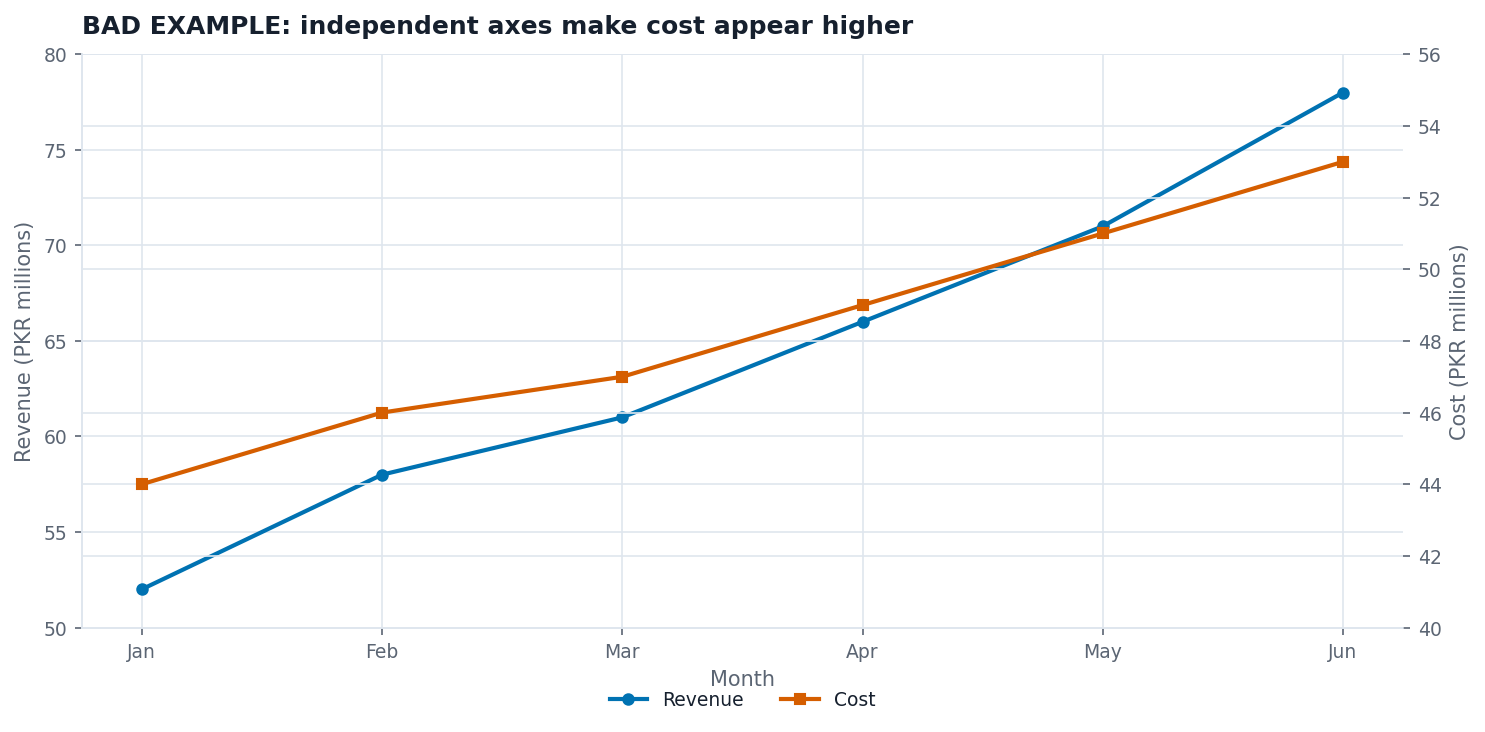

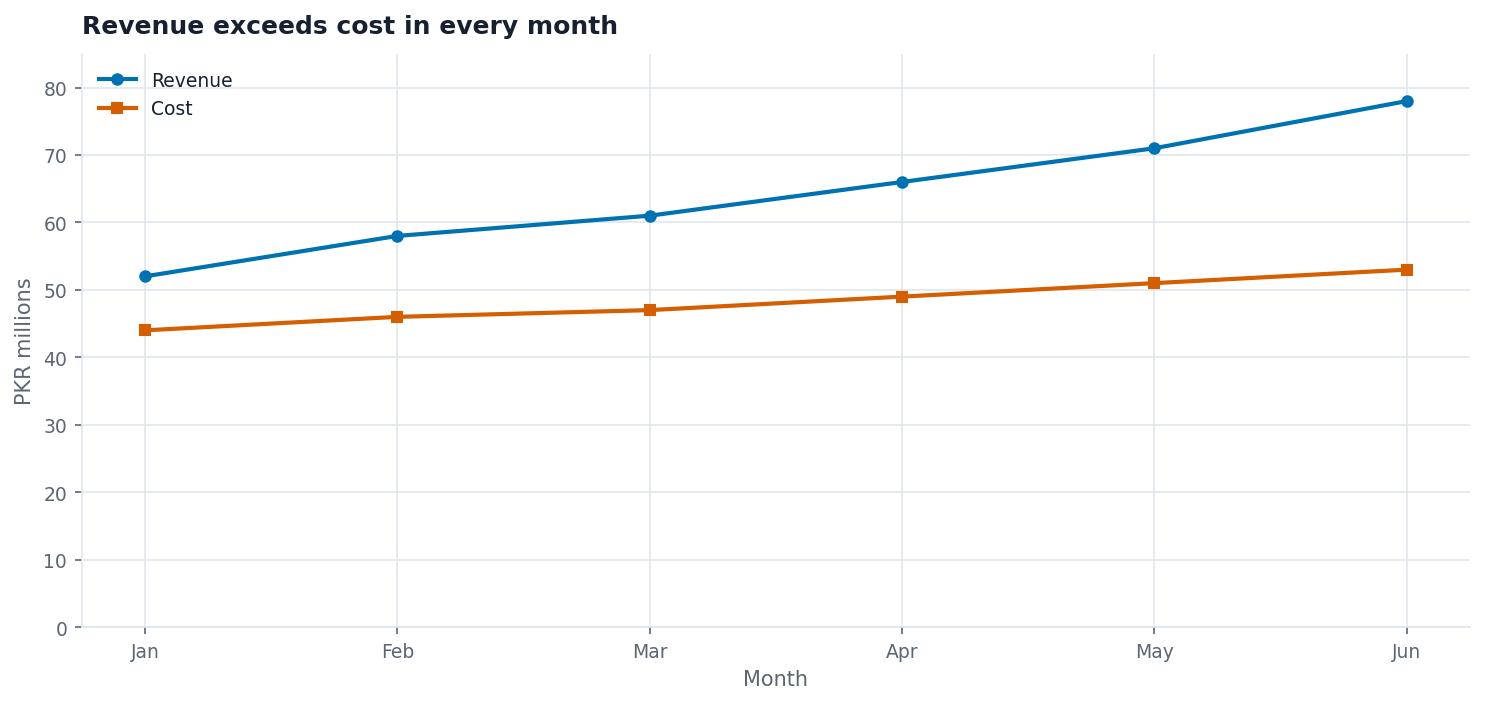

In [14]:
series = pd.read_csv(DATA_DIR / "case07_dual_axis_series.csv")
series["margin_pkr_m"] = series["revenue_pkr_m"] - series["cost_pkr_m"]
print("Monthly revenue, cost, and operating margin (PKR millions):")
display(series.set_index("month").round(1))
print(f"Months with cost above revenue: {(series['cost_pkr_m'] > series['revenue_pkr_m']).sum()}")

fig, ax = plt.subplots(figsize=(10, 4.8))
revenue_line, = ax.plot(series["month"], series["revenue_pkr_m"], marker="o", color=PALETTE_3[0], label="Revenue")
ax.set_ylim(50, 80)
ax.set_ylabel("Revenue (PKR millions)")
ax.set_xlabel("Month")
ax.set_title("BAD EXAMPLE: independent axes make cost appear higher")
ax2 = ax.twinx()
cost_line, = ax2.plot(series["month"], series["cost_pkr_m"], marker="s", color=PALETTE_3[1], label="Cost")
ax2.set_ylim(40, 56)
ax2.set_ylabel("Cost (PKR millions)")
fig.legend([revenue_line, cost_line], ["Revenue", "Cost"], loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.02))
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(series["month"], series["revenue_pkr_m"], marker="o", color=PALETTE_3[0], label="Revenue")
ax.plot(series["month"], series["cost_pkr_m"], marker="s", color=PALETTE_3[1], label="Cost")
ax.set_ylim(0, 85)
ax.set_ylabel("PKR millions")
ax.set_xlabel("Month")
ax.set_title("Revenue exceeds cost in every month")
ax.legend()
fig.tight_layout()
plt.show()

**Diagnosis and explanation.** The shared units are already PKR millions, but the bad chart assigns unrelated ranges (50–80 and 40–56); this makes cost appear above revenue for January through April. The data show the reverse in every month: revenue minus cost is +8, +12, +14, +17, +20, and +25 million PKR from January to June. The redesign uses one shared scale and zero baseline. A Lie Factor is not meaningful here because there is no single common graphic effect or shared scale to compare with the data effect.

### A8 · Bin width changes the apparent distribution

Plot systolic blood pressure with the three requested bin counts. Keep each panel independent, report n in every panel, and add a data-adaptive Freedman–Diaconis histogram as a redesign.

Non-missing systolic observations: n = 10,000 (self-check 10,000)
Freedman–Diaconis rule: 29 bins, mean bin width 3.69 mmHg


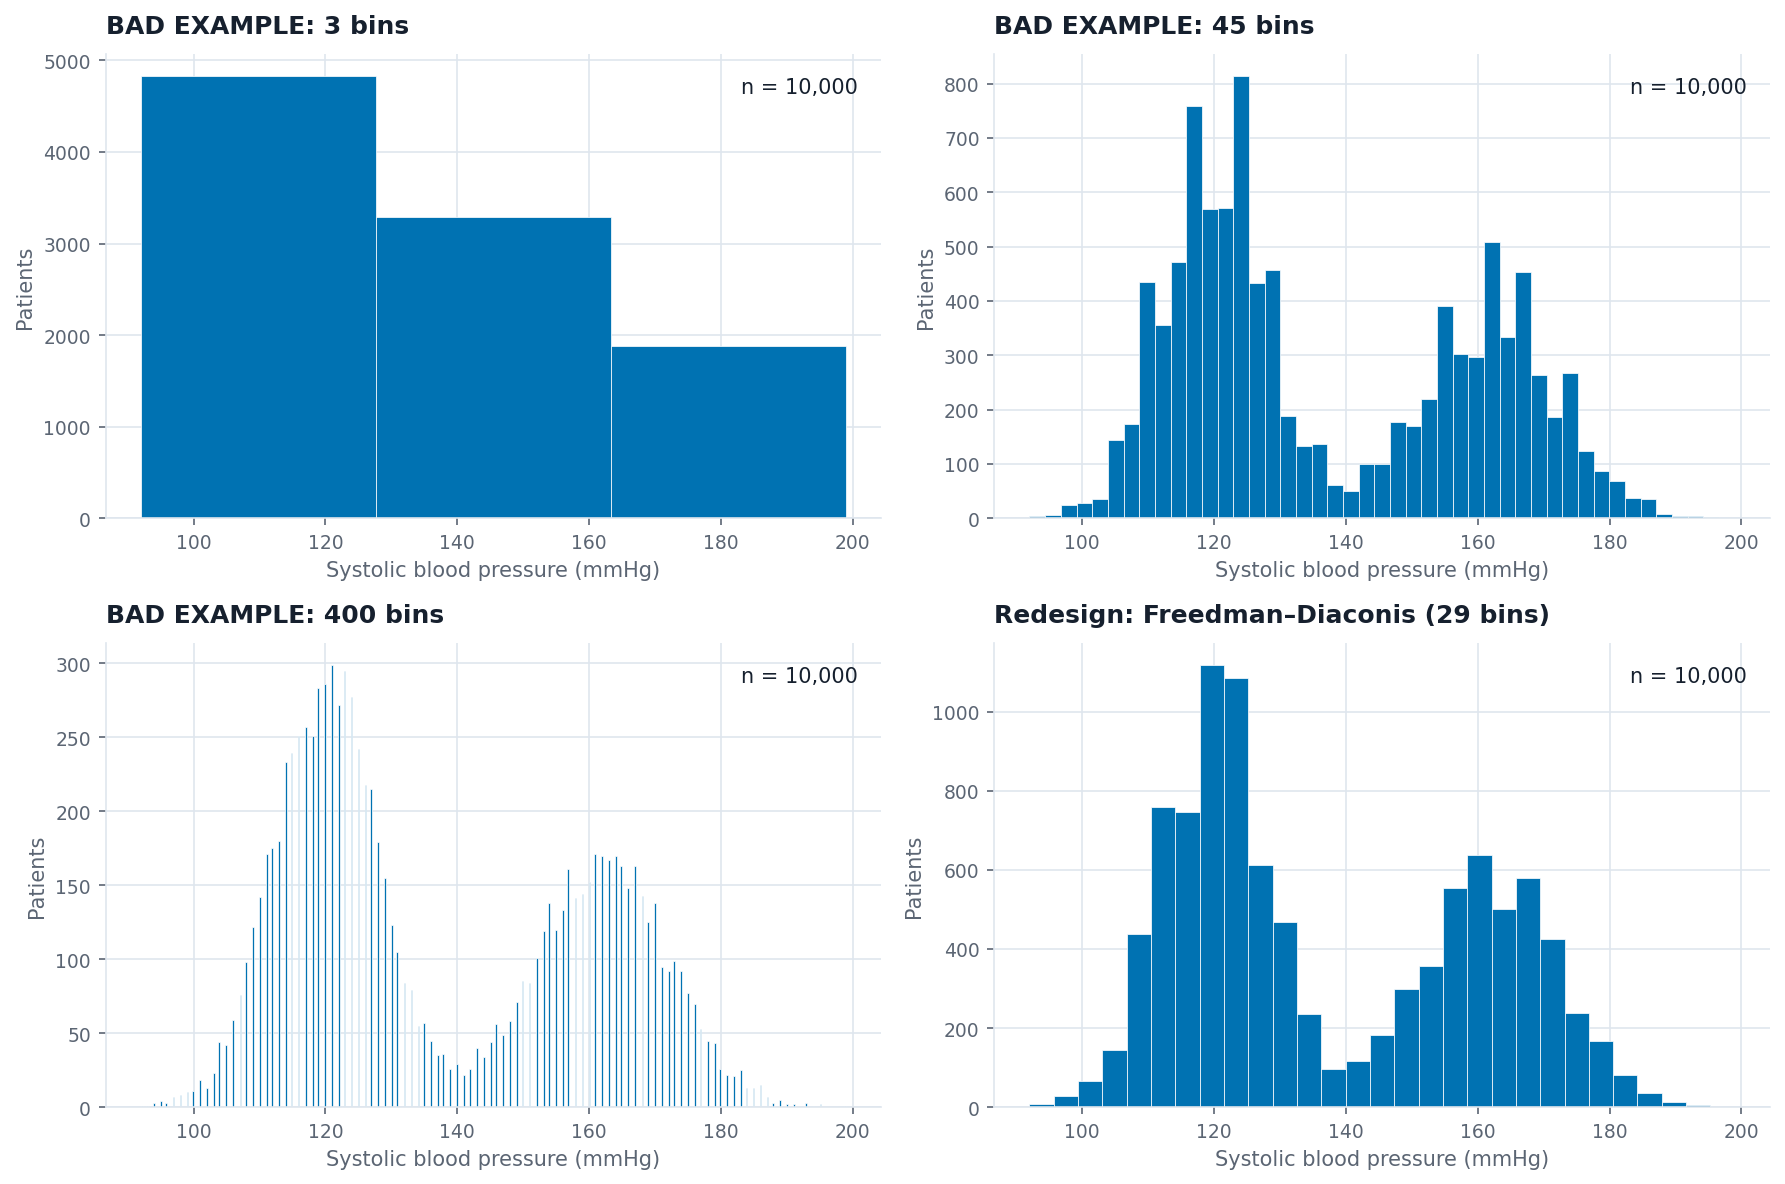

In [15]:
vitals_hist = pd.read_csv(DATA_DIR / "vitals_10k.csv", usecols=["systolic"])
systolic = vitals_hist["systolic"].dropna()
fd_edges = np.histogram_bin_edges(systolic, bins="fd")
fd_bins = len(fd_edges) - 1
fd_width = np.diff(fd_edges).mean()
print(f"Non-missing systolic observations: n = {len(systolic):,} (self-check 10,000)")
print(f"Freedman–Diaconis rule: {fd_bins} bins, mean bin width {fd_width:.2f} mmHg")

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
histogram_specs = [
    (3, "BAD EXAMPLE: 3 bins"),
    (45, "BAD EXAMPLE: 45 bins"),
    (400, "BAD EXAMPLE: 400 bins"),
    (fd_edges, f"Redesign: Freedman–Diaconis ({fd_bins} bins)"),
]
for ax, (bins, title) in zip(axes.flat, histogram_specs):
    ax.hist(systolic, bins=bins, color=PALETTE_3[0], edgecolor="white", linewidth=0.35)
    ax.text(0.97, 0.95, f"n = {len(systolic):,}", transform=ax.transAxes, ha="right", va="top")
    ax.set_title(title)
    ax.set_xlabel("Systolic blood pressure (mmHg)")
    ax.set_ylabel("Patients")
fig.tight_layout()
plt.show()

**Diagnosis and explanation.** All panels contain the same 10,000 readings. Three bins merge the two broad systolic clusters; 400 bins make small count fluctuations look like fine structure. The Freedman–Diaconis rule gives a reproducible, data-adaptive comparison (29 bins, mean width 3.69 mmHg), but bin choice still changes appearance rather than the underlying observations. The redesign makes the broad distribution visible without treating 400 tiny bars as meaningful detail.

### A9 · KDE smoothing crosses a physical ceiling

Rebuild the default-bandwidth SpO₂ KDE on an axis extending to 108%, mark the 100% ceiling, and check the actual maximum and count above it. Redesign with observed integer-value counts.

Observed SpO₂ maximum: 100% (self-check 100%)
Observed readings above 100%: 0
Readings exactly at 100%: 304 of 10,000


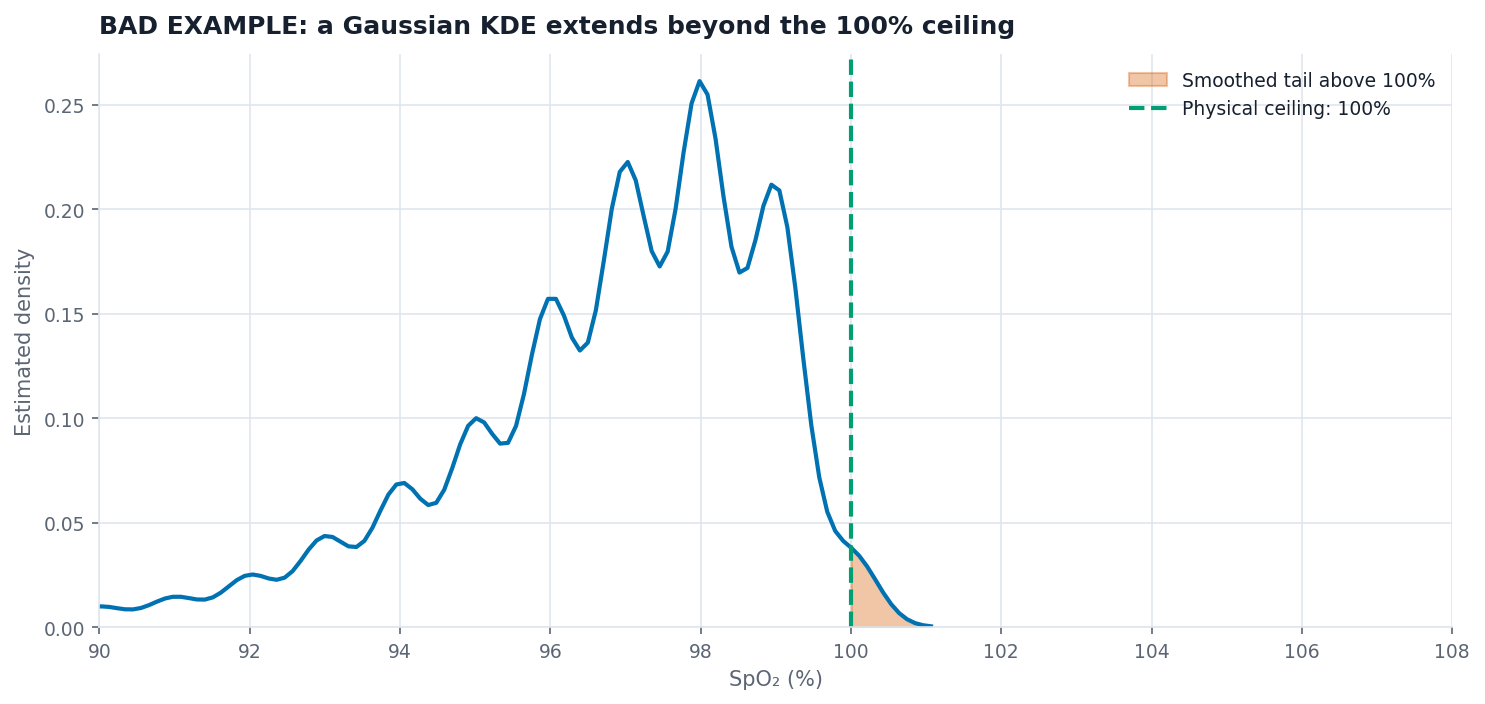

Scott KDE area above 100%: 1.551% of the displayed density


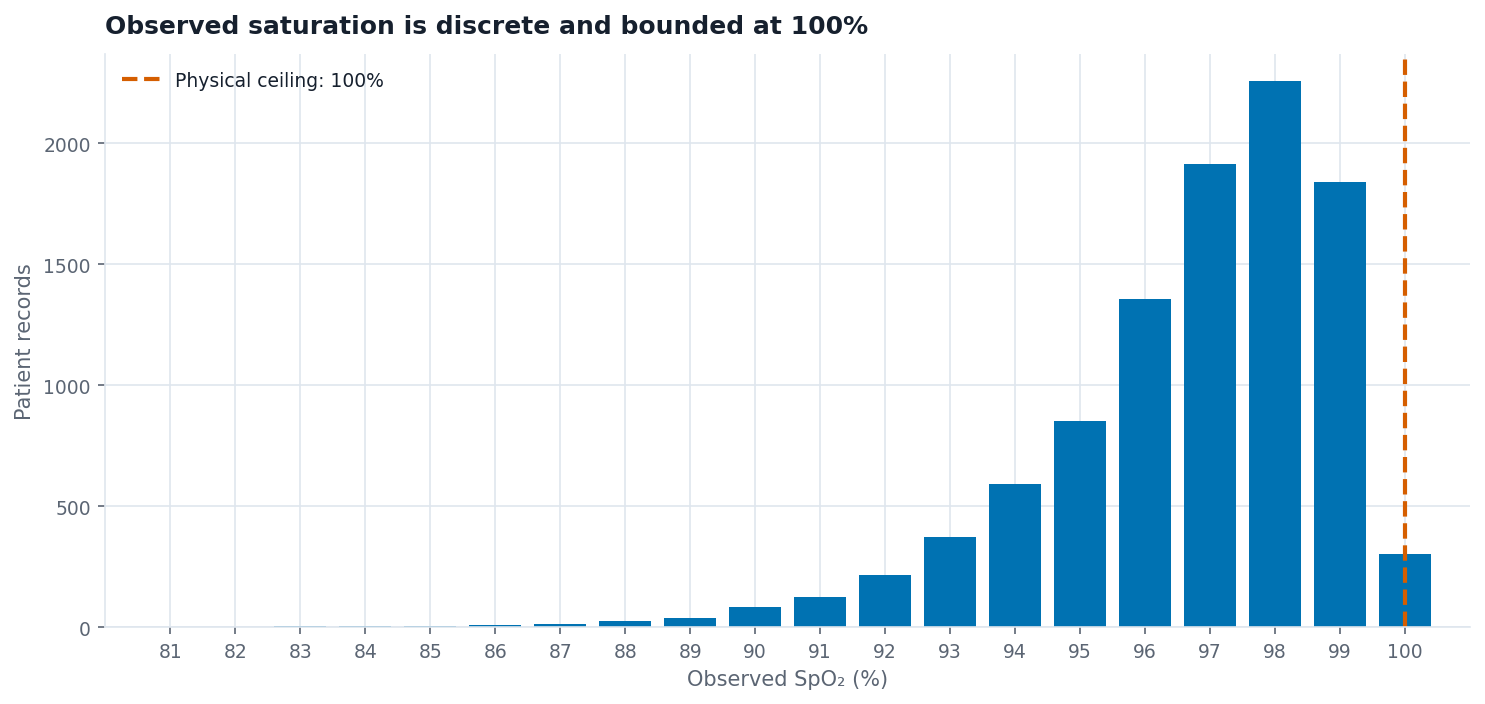

In [17]:
spo2 = pd.read_csv(DATA_DIR / "vitals_10k.csv", usecols=["spo2"])["spo2"].dropna()
spo2_max = int(spo2.max())
spo2_above_ceiling = int((spo2 > 100).sum())
print(f"Observed SpO₂ maximum: {spo2_max}% (self-check 100%)")
print(f"Observed readings above 100%: {spo2_above_ceiling}")
print(f"Readings exactly at 100%: {(spo2 == 100).sum():,} of {len(spo2):,}")

fig, ax = plt.subplots(figsize=(10, 4.8))
sns.kdeplot(x=spo2, bw_method="scott", bw_adjust=1, cut=3, color=PALETTE_3[0], ax=ax)
kde_line = ax.lines[0]
kde_x, kde_y = kde_line.get_data()
above_ceiling = kde_x > 100
tail_area = np.trapezoid(kde_y[above_ceiling], kde_x[above_ceiling])
total_area = np.trapezoid(kde_y, kde_x)
tail_fraction = tail_area / total_area
ax.fill_between(kde_x, kde_y, where=above_ceiling, color=PALETTE_3[1], alpha=0.35, label="Smoothed tail above 100%")
ax.axvline(100, color=PALETTE_3[2], linestyle="--", label="Physical ceiling: 100%")
ax.set_xlim(90, 108)
ax.set_xlabel("SpO₂ (%)")
ax.set_ylabel("Estimated density")
ax.set_title("BAD EXAMPLE: a Gaussian KDE extends beyond the 100% ceiling")
ax.legend()
fig.tight_layout()
plt.show()
print(f"Scott KDE area above 100%: {tail_fraction:.3%} of the displayed density")

spo2_counts = spo2.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.bar(spo2_counts.index, spo2_counts.values, width=0.8, color=PALETTE_3[0])
ax.axvline(100, color=PALETTE_3[1], linestyle="--", label="Physical ceiling: 100%")
ax.set_xlim(float(spo2.min()) - 1, 101)
ax.set_xticks(np.arange(int(spo2.min()), 101, 1))
ax.set_xlabel("Observed SpO₂ (%)")
ax.set_ylabel("Patient records")
ax.set_title("Observed saturation is discrete and bounded at 100%")
ax.legend()
fig.tight_layout()
plt.show()

**Diagnosis and explanation.** The raw data have a hard maximum of 100% and zero readings above it; 304 records are exactly at 100%. A Gaussian KDE uses unbounded kernels, so smoothing the mass at the ceiling creates a tail above 100% even though no patient has such a reading. With the stated Scott bandwidth (`bw_adjust=1`, `cut=3`), the rendered tail is 1.551% of estimated area, not the brief's claimed 4.4%; neither percentage is a share of observed patients. The redesign counts the discrete measurements and preserves the physical ceiling.